# TME 6015 Final project, step 1: models for load-shape archetypes (Keras)
**Name:** Lance Keddy
**Dataset:** `dataset_aug.csv` from `make_dataset_v2.py` (EnerNOC + BDG2), 12 synthetic monthly bills + metadata, 4 load-shape archetypes
**Purpose:** build a dense net and a 1-D CNN in two phases each. Phase 1 fits the training data first (raise capacity or epochs until training accuracy is high). Phase 2 then reduces overfitting one method at a time. The two final models are tuned with K-fold cross-validation, compared with each other, and given an operating point for the target below.

**Gen AI use:** generative AI was used to assist in developing the code in this notebook (course policy: code assistance only).

**Lecture references:** comments tag the slide deck a method comes from, e.g. "(week 5/6)". Methods marked "not covered in the lectures" are tools I have to justify myself.

## Target
The use case is finding buildings whose load drops on weekends and at night ("shaveable": `daytime_weekday` and `weekday_moderate`). Missing one costs more than a false alarm, so recall comes first (week 4, "which metric to use": use recall when false negatives are more expensive than false positives).

In [1]:
TARGET_RECALL = 0.90      # recall >= 0.90 on daytime_weekday and weekday_moderate
TARGET_PRECISION = 0.75   # precision >= 0.75 is acceptable
SHAVEABLE = ["daytime_weekday", "weekday_moderate"]
TRAIN_ACC_GOAL = 0.95     # phase 1 goal: training accuracy to reach before any regularization
SAVE_FIGS = False         # set to True to save every figure into figures_01/
print(f"Target: recall >= {TARGET_RECALL} on {SHAVEABLE}; precision >= {TARGET_PRECISION} acceptable")

Target: recall >= 0.9 on ['daytime_weekday', 'weekday_moderate']; precision >= 0.75 acceptable


## Setup: imports, seeds, data

In [2]:
import os, time, random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers, regularizers
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (confusion_matrix, balanced_accuracy_score, classification_report,
                             recall_score, precision_score, accuracy_score, roc_curve, roc_auc_score)

SEED = 42
SPLIT_SEED = 42   # seed for the building split (test / validation / CV folds)
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
keras.utils.set_random_seed(SEED)   # same randomness each run, so runs are comparable
T_START = time.time()

# ---- Load the dataset: working folder, then the project folder, then Google Drive (folder TME6015) ----
CANDIDATES = ["dataset_aug.csv", "../data/processed_v2/dataset_aug.csv"]
PATH = next((p for p in CANDIDATES if os.path.exists(p)), None)
if PATH is None:
    from google.colab import drive; drive.mount("/content/drive")
    PATH = "/content/drive/MyDrive/TME6015/dataset_aug.csv"
df = pd.read_csv(PATH)
missing = [c for c in ["label_margin", "hours_above_80"] if c not in df.columns]
assert not missing, (f"{PATH} is the OLD dataset_aug.csv (no {missing}). Upload the new dataset_aug.csv "
                     "made by the updated make_dataset_v2.py to MyDrive/TME6015/ and rerun.")
print(PATH, "|", df.shape, "rows x cols |", df.building_key.nunique(), "unique buildings")
df.head()

Mounted at /content/drive
/content/drive/MyDrive/TME6015/dataset_aug.csv | (21896, 40) rows x cols | 1322 unique buildings


,uid,offset_days,kwh_m01,kwh_m02,kwh_m03,kwh_m04,kwh_m05,kwh_m06,kwh_m07,kwh_m08,...,sq_ft,lat,lng,region,resolution_min,year,archetype,cluster,label_margin,hours_above_80
0,bdg2_Bear_assembly_Angel_2017,0,404390.154312,410067.591812,323646.108086,288090.843582,354367.390793,329564.178314,319369.684204,301497.279144,...,238065.0,37.871903,-122.260729,US_West,60,2017,daytime_7day,1,0.042,84.0
1,bdg2_Bear_assembly_Angel_2017,3,412279.725952,395842.083908,312741.772606,297282.623596,355077.002960,325653.089600,317177.745651,318837.580643,...,238065.0,37.871903,-122.260729,US_West,60,2017,daytime_7day,1,0.042,84.0
2,bdg2_Bear_assembly_Angel_2017,6,425693.257355,378301.104797,312143.378365,300240.680145,356456.266235,323707.058594,313025.837616,335241.703522,...,238065.0,37.871903,-122.260729,US_West,60,2017,daytime_7day,1,0.042,84.0
3,bdg2_Bear_assembly_Angel_2017,9,443622.155899,366211.889557,307912.457939,302035.760208,354865.197510,324349.297760,312076.096588,336621.835007,...,238065.0,37.871903,-122.260729,US_West,60,2017,daytime_7day,1,0.042,84.0
4,bdg2_Bear_assembly_Angel_2017,12,456543.750977,345322.895744,309979.979065,306439.088913,350033.690369,325998.766785,307508.549561,345045.305267,...,238065.0,37.871903,-122.260729,US_West,60,2017,daytime_7day,1,0.042,84.0


In [3]:
# Reproducibility information: library versions used for this run
import sys, sklearn
print("python", sys.version.split()[0], "| tensorflow", tf.__version__, "| keras", keras.__version__,
      "| scikit-learn", sklearn.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

python 3.13.16 | tensorflow 2.21.0 | keras 3.13.2 | scikit-learn 1.6.1 | numpy 2.4.6 | pandas 2.2.3


## Features
Same feature block as notebook 00: monthly kWh share and relative peak (shape, not size), monthly load factor, size as log(annual kWh) and log(sq ft), latitude, a flag for hourly data, and the categorical columns building type and region turned into 0/1 columns. These are synthetic features built from the raw bills (week 4: synthetic features, numerical vs categorical data; the 0/1 "one-hot" coding itself is not named in the slides).

Columns that are never model inputs: `label_margin` and `hours_above_80` (computed from the interval data the label comes from), `archetype` and `cluster` (the label itself), and the ID/bookkeeping columns `uid`, `building_key`, `year`, `sub_type`, `source`.

In [4]:
MONTHS = range(1, 13)
def make_features(d):
    """Feature block from 12 monthly kWh + 12 billed peaks + metadata (same as notebook 00)."""
    kwh = d[[f"kwh_m{m:02d}" for m in MONTHS]].values
    pk  = d[[f"peak_kw_billed_m{m:02d}" for m in MONTHS]].values
    f = pd.DataFrame({
        **{f"kwh_share_m{m:02d}": kwh[:, i] / kwh.sum(1) * 12 for i, m in enumerate(MONTHS)},   # seasonality
        **{f"peak_rel_m{m:02d}":  pk[:, i]  / pk.max(1)        for i, m in enumerate(MONTHS)},   # peak pattern
        **{f"lf_m{m:02d}":        kwh[:, i] / (pk[:, i] * 730) for i, m in enumerate(MONTHS)},   # monthly load factor
        "log_annual_kwh": np.log10(kwh.sum(1)),
        "log_sq_ft": np.log10(d.sq_ft.clip(lower=100)).values,
        "lat": d.lat.values,
        "hourly_source": (d.resolution_min == 60).astype(float).values,
    })
    # categorical -> numerical (week 4): one 0/1 column per building type and per region
    f = pd.concat([f, pd.get_dummies(d.building_type, prefix="type").astype(float).reset_index(drop=True),
                      pd.get_dummies(d.region, prefix="region").astype(float).reset_index(drop=True)], axis=1)
    return f.fillna(0)

features = make_features(df)

NEVER_INPUTS = ["label_margin", "hours_above_80", "cluster", "archetype", "uid", "building_key", "year", "sub_type", "source"]
assert not set(NEVER_INPUTS) & set(features.columns), "a leakage column slipped into the features"

classes = sorted(df.archetype.unique())
y_all = df.archetype.map({c: i for i, c in enumerate(classes)}).values
groups = df.building_key.values
shave_idx = [classes.index(c) for c in SHAVEABLE]
print(features.shape[1], "features;", "classes:", classes)

55 features; classes: ['daytime_7day', 'daytime_weekday', 'flat_7day', 'weekday_moderate']


## Split by building (not by row)
Training, validation and test sets (week 8/9). The split is made on *buildings*, not rows: each building has 10 augmented copies, and copies of one building in two sets would let the model recognize the building. `StratifiedGroupKFold` makes 5 folds of buildings while keeping the class mix similar in each fold (grouping and stratifying are not covered in the lectures). Fold 0 buildings are the test set, fold 1 buildings the validation set, the other 3 folds training. Validation and test use only the un-augmented copy (`offset_days == 0`).

Training rows: every model trains on the **un-augmented** training rows (one row per building-year, so one epoch = one pass over the training buildings), except the models that test data augmentation, which use all 10 billing-offset copies (`x_train_aug`).

"Confident" test rows are rows whose label is at least 0.1 away from a rule threshold (`label_margin >= 0.1`). `label_margin` is only used to pick these rows, never as an input.

In [5]:
base = (df.offset_days == 0).values
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SPLIT_SEED)
folds = list(sgkf.split(features[base], y_all[base], groups[base]))
test_b  = np.unique(groups[base][folds[0][1]])
val_b   = np.unique(groups[base][folds[1][1]])
train_b = np.setdiff1d(np.unique(groups), np.concatenate([test_b, val_b]))
assert not (set(test_b) & set(val_b) or set(test_b) & set(train_b) or set(val_b) & set(train_b)), "a building is in two splits"

is_train_aug = np.isin(groups, train_b)          # all 10 copies of the training buildings (augmentation models only)
is_train = is_train_aug & base                   # un-augmented training rows (all other models)
is_val   = np.isin(groups, val_b)  & base
is_test  = np.isin(groups, test_b) & base

# Standardization (week 8/9, data preprocessing): mean 0, std 1, using TRAINING statistics only
mu, sd = features[is_train_aug].mean(), features[is_train_aug].std().replace(0, 1)
Xz = ((features - mu) / sd).values.astype("float32")
x_train, y_train = Xz[is_train], y_all[is_train]
x_train_aug, y_train_aug = Xz[is_train_aug], y_all[is_train_aug]
x_val,   y_val   = Xz[is_val],   y_all[is_val]
x_test,  y_test  = Xz[is_test],  y_all[is_test]
conf_test = (df.label_margin[is_test] >= 0.1).values    # confident test rows

for name, m, b in [("train", is_train, train_b), ("train, 10 copies", is_train_aug, train_b),
                   ("validation", is_val, val_b), ("test", is_test, test_b)]:
    print(f"{name:<17} {m.sum():>6} rows  {len(b):>5} buildings")
print("test rows per class (all vs confident):")
print(pd.DataFrame({"all": pd.Series(y_test).map(dict(enumerate(classes))).value_counts(),
                    "confident": pd.Series(y_test[conf_test]).map(dict(enumerate(classes))).value_counts()}).loc[classes])

# Imbalanced dataset (week 8/9 defines it). The remedy used here, class weights in the loss, is not covered in the lectures:
# each class's weight = rows / (4 x rows in that class), so the smaller classes count more. Kept the same for every model.
def make_class_weight(y):
    counts = np.bincount(y, minlength=len(classes))
    return {i: len(y) / (len(classes) * c) for i, c in enumerate(counts)}
class_weight = make_class_weight(y_train)
print({classes[i]: round(w, 2) for i, w in class_weight.items()})

train               1318 rows    794 buildings
train, 10 copies   13179 rows    794 buildings
validation           432 rows    264 buildings
test                 441 rows    264 buildings
test rows per class (all vs confident):
                  all  confident
daytime_7day       85         12
daytime_weekday   103         79
flat_7day         187        107
weekday_moderate   66          6
{'daytime_7day': np.float64(1.22), 'daytime_weekday': np.float64(0.91), 'flat_7day': np.float64(0.72), 'weekday_moderate': np.float64(1.45)}


## Shared helpers
- `plot_history`: accuracy and loss curves, train vs validation (Assignment 1 helper; generalization curve, week 5/6).
- `evaluate`: test-set report and confusion matrix (week 4: confusion matrix, accuracy, precision, recall). **Balanced accuracy** is not covered in the lectures: it is the average of the per-class recalls, used because week 4 says to avoid plain accuracy on imbalanced data.
- `finish`: the running table (as the Assignment 1 `evaluate()` did). Phase-1 models also get a mechanical rule check; phase-2 and tuned models get a comparison with their parent instead. The phase-1 rule:
  - train accuracy below `TRAIN_ACC_GOAL` and still rising over the last 5 epochs -> underfitting, train for more epochs (week 3: epochs; week 5/6);
  - train accuracy below the goal and flat -> underfitting, add capacity: more layers or units (week 5/6: model complexity);
  - train accuracy at or above the goal and a train/validation gap of 0.10 or more -> overfitting, regularize (week 5/6).

In [6]:
if SAVE_FIGS: os.makedirs("figures_01", exist_ok=True)
def show(fname):
    """Save the current figure if SAVE_FIGS is on, then show it."""
    if SAVE_FIGS: plt.savefig(f"figures_01/{fname}.png", dpi=130, bbox_inches="tight")
    plt.show()

def plot_history(history, title):
    """Accuracy and loss curves, train vs validation (Assignment 1 helper)."""
    h = history.history
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(h["accuracy"], label="train"); ax[0].plot(h["val_accuracy"], label="validation")
    ax[0].axhline(TRAIN_ACC_GOAL, ls=":", color="k", lw=1, label="train goal")
    ax[0].set_title(f"{title}: accuracy"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(h["loss"], label="train"); ax[1].plot(h["val_loss"], label="validation")
    ax[1].set_title(f"{title}: error (loss)"); ax[1].set_xlabel("epoch"); ax[1].legend()
    show(f"history_{title}")

def scores(y_true, pred):
    """Accuracy, balanced accuracy, per-class recall/precision (week 4), and the shaveable-vs-not view."""
    r = recall_score(y_true, pred, labels=range(len(classes)), average=None, zero_division=0)
    p = precision_score(y_true, pred, labels=range(len(classes)), average=None, zero_division=0)
    out = {"acc": accuracy_score(y_true, pred), "bal_acc": balanced_accuracy_score(y_true, pred)}
    for i, c in enumerate(classes):
        out[f"recall_{c}"] = r[i]; out[f"precision_{c}"] = p[i]
    # shaveable = daytime_weekday or weekday_moderate (positive), everything else negative (binary view, week 4)
    t, q = np.isin(y_true, shave_idx), np.isin(pred, shave_idx)
    out["shave_recall"] = recall_score(t, q, zero_division=0); out["shave_precision"] = precision_score(t, q, zero_division=0)
    return out

results = []                       # test scores, one row per model
val_proba, test_proba = {}, {}     # kept for the operating-point section
def evaluate(name, y_true, proba_or_pred, confident=None):
    """Test-set report and confusion matrix (week 4); appends scores on all and confident test rows to `results`."""
    confident = conf_test if confident is None else confident
    out = np.asarray(proba_or_pred)
    pred = out.argmax(1) if out.ndim == 2 else out
    print(classification_report(y_true, pred, target_names=classes, digits=3, zero_division=0))
    cm = confusion_matrix(y_true, pred, labels=range(len(classes)))
    fig, ax = plt.subplots(figsize=(4.5, 4)); ax.imshow(cm, cmap="Blues")
    for i in range(len(classes)):
        for j in range(len(classes)):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="w" if cm[i, j] > cm.max() / 2 else "k")
    ax.set_xticks(range(len(classes))); ax.set_xticklabels(classes, rotation=45, ha="right"); ax.set_yticks(range(len(classes))); ax.set_yticklabels(classes)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"{name}: confusion matrix ({len(y_true)} test rows)")
    plt.tight_layout(); show(f"confusion_{name}")
    row = {"model": name}
    row.update({f"all_{k}": v for k, v in scores(y_true, pred).items()})
    row.update({f"conf_{k}": v for k, v in scores(y_true[confident], pred[confident]).items()})
    results.append(row)
    return row

GAP_LIMIT, RISE_LIMIT = 0.10, 0.01
def rule_check(h):
    """Mechanical rule (week 5/6: underfitting vs overfitting). Returns one line of text."""
    acc, gap = h["accuracy"][-1], h["accuracy"][-1] - h["val_accuracy"][-1]
    rise = np.mean(h["accuracy"][-3:]) - np.mean(h["accuracy"][-8:-5]) if len(h["accuracy"]) >= 8 else np.nan
    if acc < TRAIN_ACC_GOAL and rise >= RISE_LIMIT:
        return f"train acc {acc:.3f} < goal {TRAIN_ACC_GOAL}, still rising ({rise:+.3f} over the last 5 epochs) -> underfitting: train for more epochs"
    if acc < TRAIN_ACC_GOAL:
        return f"train acc {acc:.3f} < goal {TRAIN_ACC_GOAL}, flat ({rise:+.3f} over the last 5 epochs) -> underfitting: add capacity (more layers or units)"
    if gap >= GAP_LIMIT:
        return f"train acc {acc:.3f} >= goal {TRAIN_ACC_GOAL}, gap {gap:.3f} >= {GAP_LIMIT} -> overfitting: regularize"
    return f"train acc {acc:.3f} >= goal {TRAIN_ACC_GOAL}, gap {gap:.3f} < {GAP_LIMIT} -> good fit"

runs = {}                          # the running table, one row per model
def finish(name, phase, change, model, history, xv=None, xt=None, parent=None):
    """Curves, running-table row, rule check, then test scores through evaluate()."""
    xv = x_val if xv is None else xv; xt = x_test if xt is None else xt
    h = history.history
    plot_history(history, name)
    val_proba[name], test_proba[name] = model.predict(xv, verbose=0), model.predict(xt, verbose=0)
    runs[name] = dict(phase=phase, change=change, train_acc=h["accuracy"][-1], val_acc=h["val_accuracy"][-1],
                      best_val_acc=max(h["val_accuracy"]), gap=h["accuracy"][-1] - h["val_accuracy"][-1],
                      val_loss_end=h["val_loss"][-1], epochs=len(h["loss"]), params=model.count_params(),
                      val_bal_acc=balanced_accuracy_score(y_val, val_proba[name].argmax(1)), parent=parent)
    r = runs[name]
    r["test_bal_acc"] = evaluate(name, y_test, test_proba[name])["all_bal_acc"]
    print(f"{name}: train acc {r['train_acc']:.3f} | val acc {r['val_acc']:.3f} (best {r['best_val_acc']:.3f}) | gap {r['gap']:+.3f} | "
          f"val loss {r['val_loss_end']:.3f} | epochs {r['epochs']} | params {r['params']:,} | val bal acc {r['val_bal_acc']:.3f}")
    if phase == 1:
        print("rule:", rule_check(h))
    elif parent and phase == "tuned":
        p = runs[parent]
        print(f"vs {parent} before tuning: train acc {p['train_acc']:.3f} -> {r['train_acc']:.3f}, val acc {p['val_acc']:.3f} -> {r['val_acc']:.3f}, "
              f"gap {p['gap']:.3f} -> {r['gap']:.3f}, val bal acc {p['val_bal_acc']:.3f} -> {r['val_bal_acc']:.3f}")
    elif parent:
        p = runs[parent]
        print(f"vs parent {parent}: train acc {p['train_acc']:.3f} -> {r['train_acc']:.3f}, val acc {p['val_acc']:.3f} -> {r['val_acc']:.3f}, "
              f"gap {p['gap']:.3f} -> {r['gap']:.3f}, val bal acc {p['val_bal_acc']:.3f} -> {r['val_bal_acc']:.3f}, "
              f"val loss {p['val_loss_end']:.3f} -> {r['val_loss_end']:.3f} "
              "(regularization lowers training accuracy on purpose; judge by validation and the gap)")

def block_table(names):
    """Rows of the running table for one block, with the change against the parent for phase-2 models."""
    t = pd.DataFrame(runs).T.loc[names]
    out = t[["train_acc", "val_acc", "gap", "epochs", "val_bal_acc"]].copy()
    out.insert(0, "label", [LABELS.get(n, n) for n in names])
    if (t["phase"] == 2).any():
        par = t["parent"]
        out["parent"] = par
        out["val_bal_acc_vs_parent"] = [runs[n]["val_bal_acc"] - runs[p]["val_bal_acc"] for n, p in zip(names, par)]
        out["gap_vs_parent"] = [runs[n]["gap"] - runs[p]["gap"] for n, p in zip(names, par)]
    num = [c for c in out.columns if c not in ("label", "parent")]
    out[num] = out[num].astype(float).round(3)
    with pd.option_context("display.max_colwidth", None, "display.max_columns", None, "display.width", 250):
        display(out)

def early_stop():
    """Early stopping (week 5/6): stop when validation loss has not improved for 10 epochs, keep the best weights."""
    return keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

def step_decay(initial_lr=1e-3, drop_rate=0.5, epoch_drop=10):
    """Step decay schedule (week 5/6): LearningRate = InitialLearningRate * DropRate^floor(Epoch / EpochDrop).
    Halve the rate every 10 epochs, as in the slide example."""
    return keras.callbacks.LearningRateScheduler(
        lambda epoch, lr: float(initial_lr * drop_rate ** np.floor(epoch / epoch_drop)))

## Model-building helpers
The CNN inputs, a builder that makes any dense net or CNN from a short description (its "spec"), and the phase-2 machinery (parent rule, the list of regularization methods, the combination loop). The phase-1 models below are still written out in full; phase 2 builds its models from the parent's spec so it works for whichever parent phase 1 produces.

In [7]:
# CNN inputs: input A = 12 months x 2 channels (kWh share, relative peak); input B = every other feature
seq_cols  = [f"kwh_share_m{m:02d}" for m in MONTHS] + [f"peak_rel_m{m:02d}" for m in MONTHS]
rest_cols = [c for c in features.columns if c not in seq_cols]
col = {c: i for i, c in enumerate(features.columns)}
def to_seq(X):
    """(rows, features) -> (rows, 12 months, 2 channels)."""
    share = X[:, [col[f"kwh_share_m{m:02d}"] for m in MONTHS]]
    peak  = X[:, [col[f"peak_rel_m{m:02d}"] for m in MONTHS]]
    return np.stack([share, peak], axis=-1)
def to_rest(X): return X[:, [col[c] for c in rest_cols]]
seq_train, seq_val, seq_test = to_seq(x_train), to_seq(x_val), to_seq(x_test)
rest_train, rest_val, rest_test = to_rest(x_train), to_rest(x_val), to_rest(x_test)
seq_train_aug, rest_train_aug = to_seq(x_train_aug), to_rest(x_train_aug)
print("CNN input A", seq_train.shape, "| input B", rest_train.shape)

def callbacks_for(spec, lr=1e-3):
    """Callbacks a spec asks for. With augmentation each epoch already holds 10 copies of every building, so the
    early-stopping patience (10 epochs) and the step-decay EpochDrop (10 epochs) are scaled down by 10 (same number of weight updates)."""
    k = 10 if spec.get("aug") else 1
    cbs = []
    if spec.get("es"):
        cbs.append(keras.callbacks.EarlyStopping(monitor="val_loss", patience=max(2, 10 // k), restore_best_weights=True))
    if spec.get("decay"):
        cbs.append(step_decay(lr, epoch_drop=max(1, 10 // k)))
    return cbs

def build_from_spec(spec, kernel_size=3, pooling="max", lr=1e-3, name=None):
    """Build a dense net ("hidden" in spec) or a CNN ("filters" in spec) with the same layer order as the inline cells:
    Dense/Conv1D -> BatchNorm (if bn) -> Dropout (dense, if dropout); CNN: pooling after each conv, global average pooling,
    Dropout, join metadata, Dense 64, BatchNorm, Dropout, softmax."""
    reg = regularizers.l2(spec["l2"]) if spec.get("l2") else None
    if "hidden" in spec:                                           # dense net
        inputs = keras.Input(shape=(x_train.shape[1],)); x = inputs
        for u in spec["hidden"]:
            x = layers.Dense(u, activation="relu", kernel_regularizer=reg)(x)
            if spec.get("bn"): x = layers.BatchNormalization()(x)
            if spec.get("dropout"): x = layers.Dropout(spec["dropout"])(x)
        model_inputs = inputs
    else:                                                          # 1-D CNN
        in_seq = keras.Input(shape=(12, 2), name="monthly_sequence"); in_rest = keras.Input(shape=(len(rest_cols),), name="other_features")
        x = in_seq
        for f in spec["filters"]:
            x = layers.Conv1D(f, kernel_size=kernel_size, padding="same", activation="relu", kernel_regularizer=reg)(x)
            if spec.get("bn"): x = layers.BatchNormalization()(x)
            x = layers.MaxPooling1D(2)(x) if pooling == "max" else layers.AveragePooling1D(2)(x)
        x = layers.GlobalAveragePooling1D()(x)
        if spec.get("dropout"): x = layers.Dropout(spec["dropout"])(x)
        x = layers.concatenate([x, in_rest])
        x = layers.Dense(64, activation="relu", kernel_regularizer=reg)(x)
        if spec.get("bn"): x = layers.BatchNormalization()(x)
        if spec.get("dropout"): x = layers.Dropout(spec["dropout"])(x)
        model_inputs = [in_seq, in_rest]
    m = keras.Model(model_inputs, layers.Dense(len(classes), activation="softmax")(x), name=name)
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def inputs_for(spec, X): return X if "hidden" in spec else [to_seq(X), to_rest(X)]

def fit_from_spec(spec, X, fit_rows, stop_rows, cw, kernel_size=3, pooling="max", lr=1e-3, batch=64):
    """Train a model from its spec without curves (used by CV and learning curves). fit_rows = all copies of the training
    buildings; un-augmented specs use only their offset-0 rows. stop_rows are used only if the spec early-stops."""
    m = build_from_spec(spec, kernel_size, pooling, lr)
    rows = fit_rows if spec.get("aug") else fit_rows & base
    epochs = spec["epochs"] // 10 if spec.get("aug") else spec["epochs"]
    val = (inputs_for(spec, X[stop_rows]), y_all[stop_rows]) if spec.get("es") else None
    m.fit(inputs_for(spec, X[rows]), y_all[rows], batch_size=batch, epochs=epochs, validation_data=val,
          class_weight=cw, callbacks=callbacks_for(spec, lr), verbose=0)
    return m

def train_spec(name, phase, spec, parent, change, label, kernel_size=3, pooling="max", lr=1e-3, batch=64):
    """Build a model from its spec, show its summary, train it on the normal split and record it like the inline models."""
    print(f"{name}: {change}")
    keras.utils.set_random_seed(SEED)
    model = build_from_spec(spec, kernel_size, pooling, lr, name=name)
    model.summary()
    rows = is_train_aug if spec.get("aug") else is_train
    epochs = spec["epochs"] // 10 if spec.get("aug") else spec["epochs"]
    h = model.fit(inputs_for(spec, Xz[rows]), y_all[rows], batch_size=batch, epochs=epochs,
                  validation_data=(inputs_for(spec, x_val), y_val), class_weight=class_weight,
                  callbacks=callbacks_for(spec, lr), verbose=0)
    SPECS[name], CHANGES[name], LABELS[name] = spec, change, label
    globals()[name] = model
    finish(name, phase, change, model, h, xv=inputs_for(spec, x_val), xt=inputs_for(spec, x_test), parent=parent)
    return model

CNN input A (1318, 12, 2) | input B (1318, 31)


In [8]:
# ---- Phase-2 machinery ----
def pick_parent(prefix):
    """Phase-2 parent rule: the phase-1 model with the HIGHEST training accuracy among those that reached TRAIN_ACC_GOAL
    (instructor: "achieve the highest accuracy you can and then do regularization"); a tie within 0.005 goes to fewer parameters."""
    p1 = [n for n in runs if n.startswith(prefix) and runs[n]["phase"] == 1]
    cand = [n for n in p1 if runs[n]["train_acc"] >= TRAIN_ACC_GOAL]
    if not cand:
        print(f"WARNING: no phase-1 {prefix} model reached TRAIN_ACC_GOAL = {TRAIN_ACC_GOAL}; using the highest training accuracy instead")
        cand = p1
    top = max(runs[n]["train_acc"] for n in cand)
    parent = min([n for n in cand if runs[n]["train_acc"] >= top - 0.005], key=lambda n: runs[n]["params"])
    print("candidates (train acc, params):", {n: (round(runs[n]["train_acc"], 3), runs[n]["params"]) for n in cand})
    print("phase-2 parent:", parent)
    return parent

# The single regularization methods of phase 2: short label, description, change to the spec
METHODS = {
    "l2_small":     ("+L2 1e-5", "L2 regularization 1e-5 on every Dense / Conv1D layer (week 5/6: start with a small value)", dict(l2=1e-5)),
    "l2_strong":    ("+L2 1e-3", "a stronger L2, 1e-3 (week 5/6: increase until the model generalizes better)", dict(l2=1e-3)),
    "dropout":      ("+Dropout 0.3", "Dropout 0.3 after each hidden layer, or after global average pooling and the Dense layer in a CNN (week 5/6: rate 0.2 to 0.5)", dict(dropout=0.3)),
    "early_stop":   ("+early stopping", "early stopping on validation loss, patience 10 epochs, keep the best weights (week 5/6)", dict(es=True)),
    "batchnorm":    ("+BatchNorm", "BatchNormalization after each Dense / Conv1D layer (week 5/6)", dict(bn=True)),
    "augmentation": ("+augmentation", "data augmentation (week 8/9): all 10 billing-offset copies of each training building for 1/10 of the epochs, so the number of weight updates equals the parent's", dict(aug=True)),
    "step_decay":   ("+step decay", "step-decay learning rate (week 5/6): 1e-3 halved every 10 epochs", dict(decay=True)),
}
SHORT = {"l2_small": "L2 1e-5", "l2_strong": "L2 1e-3", "dropout": "Dropout", "early_stop": "early stop",
         "batchnorm": "BatchNorm", "augmentation": "augmentation", "step_decay": "step decay"}
PARENTS, SINGLE = {}, {"dense": {}, "cnn": {}}

def spec_with(parent_spec, methods):
    """The parent's spec plus the listed methods."""
    s = dict(parent_spec)
    for m in methods: s.update(METHODS[m][2])
    return s

def single(name, prefix, method):
    """Phase 2, step A: the parent plus ONE method."""
    parent = PARENTS[prefix]
    train_spec(name, 2, spec_with(SPECS[parent], [method]), parent, f"from {parent}: {METHODS[method][1]}", METHODS[method][0])
    SINGLE[prefix][method] = name

def combine(prefix, max_steps=4):
    """Phase 2, step B: rank the single methods by validation balanced accuracy change vs the parent, keep those that
    improved it (the two L2 strengths count as one method: the better one), start from the best one, then add the next
    method and keep it only if validation balanced accuracy improves on the current best. Validation only; test is never used."""
    parent = PARENTS[prefix]; base_val = runs[parent]["val_bal_acc"]
    gains = {m: runs[n]["val_bal_acc"] - base_val for m, n in SINGLE[prefix].items()}
    worse_l2 = "l2_small" if gains["l2_small"] < gains["l2_strong"] else "l2_strong"
    ranked = sorted([m for m in gains if m != worse_l2 and gains[m] > 0], key=lambda m: -gains[m])
    print(f"single methods, validation balanced accuracy change vs parent {parent} ({base_val:.3f}):")
    for m in sorted(gains, key=lambda m: -gains[m]):
        note = "" if m in ranked else ("  (weaker L2 strength, not used)" if m == worse_l2 and gains[m] > 0 else "  (did not improve, not used)")
        print(f"  {SHORT[m]:<13} {gains[m]:+.3f}{note}")
    if not ranked:
        print("no single method improved on the parent; the parent stays the best model")
        return parent, pd.DataFrame()
    best, best_methods = SINGLE[prefix][ranked[0]], [ranked[0]]
    print(f"start: {best} = parent + {SHORT[ranked[0]]}, val bal acc {runs[best]['val_bal_acc']:.3f}")
    log = []
    for step, m in enumerate(ranked[1:1 + max_steps], 1):
        methods = best_methods + [m]
        name, label = f"{prefix}_combo{step}", "combo: " + " + ".join(SHORT[x] for x in methods)
        print(f"\n===================== {name.upper()}: try adding {SHORT[m]} to {best} =====================")
        train_spec(name, 2, spec_with(SPECS[parent], methods), parent,
                   f"from {parent}: " + "; ".join(METHODS[x][1] for x in methods), label)
        before, after = runs[best]["val_bal_acc"], runs[name]["val_bal_acc"]
        kept = after > before
        log.append({"step": step, "model": name, "added": SHORT[m], "methods": " + ".join(SHORT[x] for x in methods),
                    "val_bal_acc_before": round(before, 3), "val_bal_acc_after": round(after, 3), "kept": kept})
        print(f"step {step}: add {SHORT[m]}: val bal acc {before:.3f} -> {after:.3f} -> {'KEPT' if kept else 'dropped'}")
        if kept:
            best, best_methods = name, methods
    print(f"\nbest {prefix} model after the loop: {best} ({' + '.join(SHORT[x] for x in best_methods)})")
    return best, pd.DataFrame(log)

---
# 1. Dense nets
Same pattern as Assignment 1: each model is written out in full and changes ONE thing from its parent. Fixed for every dense model: ReLU (week 4), softmax output over the 4 classes (week 8/9 names softmax as the final classification layer), log loss (week 4, 4-class form `sparse_categorical_crossentropy`), the Adam optimizer at learning rate 1e-3 (week 5/6), batch 64, and the same class weights.

In [9]:
# The change each model makes (long text) and a short label for the tables
CHANGES = {
    "dense0": 'none: the course base model (Dense 64 -> 64 -> 4, Adam 1e-3, batch 64), 40 epochs, no regularization.',
    "dense1": 'epochs 40 -> 80 (week 3: epochs). dense0 ended below the training goal and still rising.',
    "dense2": "3 hidden layers (128 -> 64 -> 32), same 40 epochs. The other remedy for dense0's underfitting: more capacity instead of more epochs (week 5/6: model complexity).",
    "dense3": 'a fourth hidden layer (128 -> 128 -> 64 -> 32), same 40 epochs (second step of the capacity route).',
    "cnn0": 'none: base CNN, one Conv1D layer (32 filters, kernel 3) -> MaxPool -> global average pooling -> join metadata -> Dense 64 -> softmax, 40 epochs, no regularization.',
    "cnn1": 'epochs 40 -> 100 (week 3: epochs). cnn0 ended below the training goal. Its rule line reads flat (+0.009 over the last 5 epochs, just under the 0.01 cut-off), which points to more capacity; more epochs is the cheaper change, so it is tried first.',
    "cnn2": 'a second conv layer with more filters (32 -> 64). cnn1 ended below the training goal and flat, so more capacity (week 5/6; week 8/9 LeNet: 2 conv + 2 pool).',
    "cnn3": 'a third conv layer with more filters (32 -> 64 -> 128). cnn2 still below the goal and flat.',
}
LABELS = {'dense0': 'base 64-64, 40 ep', 'dense1': '+epochs 80', 'dense2': '3 layers 128-64-32', 'dense3': '4 layers 128-128-64-32', 'cnn0': 'base 1 conv, 40 ep', 'cnn1': '+epochs 100', 'cnn2': '+conv layer (64)', 'cnn3': '+conv layer (128)'}
SPECS = {
    "dense0": {'hidden': [64, 64], 'epochs': 40},
    "dense1": {'hidden': [64, 64], 'epochs': 80},
    "dense2": {'hidden': [128, 64, 32], 'epochs': 40},
    "dense3": {'hidden': [128, 128, 64, 32], 'epochs': 40},
    "cnn0": {'filters': [32], 'epochs': 40},
    "cnn1": {'filters': [32], 'epochs': 100},
    "cnn2": {'filters': [32, 64], 'epochs': 100},
    "cnn3": {'filters': [32, 64, 128], 'epochs': 100},
}

## Dense phase 1: fit the training data first
Weeks 2, 3 and 5/6: an underfit model does not even fit the training data, so regularizing it makes no sense yet. No Dropout, no L2, no BatchNormalization, no early stopping, no learning-rate schedule, un-augmented rows. Start from the course base model and change one thing per model, following the rule printed under each model, until training accuracy reaches `TRAIN_ACC_GOAL` and validation has clearly split from training. After dense0 both remedies are shown: more epochs (dense1) and more layers (dense2, dense3). That end state is an overfit model, which is what phase 2 then works on.

---
# dense0
**Change from course base:** none: the course base model (Dense 64 -> 64 -> 4, Adam 1e-3, batch 64), 40 epochs, no regularization.

Model: "dense0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 55)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         3,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,004 (31.27 KB)

 Trainable params: 8,004 (31.27 KB)

 Non-trainable params: 0 (0.00 B)

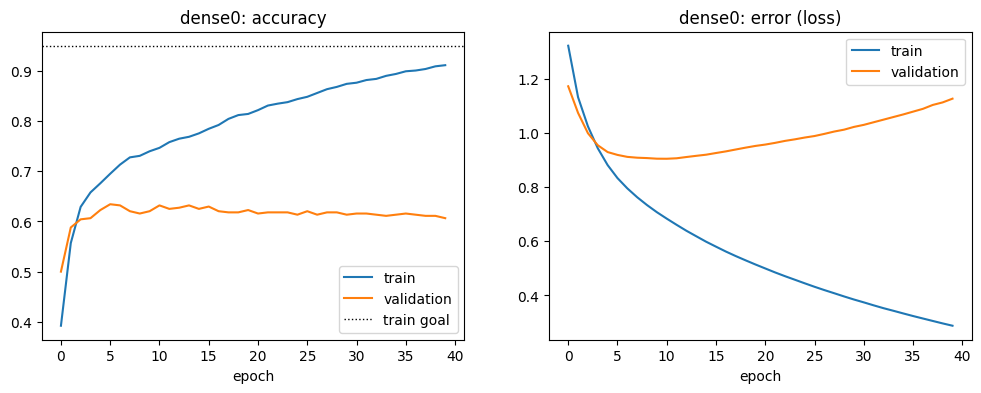

                  precision    recall  f1-score   support

    daytime_7day      0.455     0.471     0.462        85
 daytime_weekday      0.814     0.806     0.810       103
       flat_7day      0.870     0.749     0.805       187
weekday_moderate      0.400     0.545     0.462        66

        accuracy                          0.678       441
       macro avg      0.634     0.643     0.635       441
    weighted avg      0.706     0.678     0.689       441



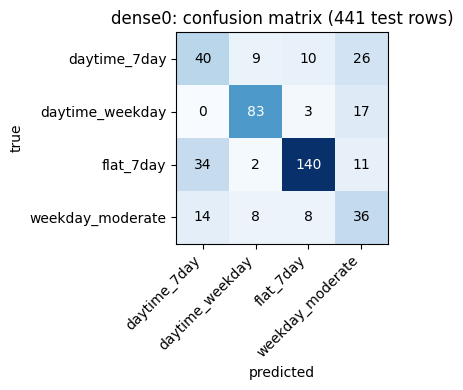

dense0: train acc 0.911 | val acc 0.606 (best 0.634) | gap +0.305 | val loss 1.126 | epochs 40 | params 8,004 | val bal acc 0.571
rule: train acc 0.911 < goal 0.95, still rising (+0.019 over the last 5 epochs) -> underfitting: train for more epochs


In [10]:
# ===================== DENSE 0 (BASE) =====================
# Course base model: 2 hidden layers (64 units each), ReLU (week 4), softmax output for 4 classes
keras.utils.set_random_seed(SEED)
inputs = keras.Input(shape=(x_train.shape[1],))
x = layers.Dense(64, activation="relu")(inputs)
x = layers.Dense(64, activation="relu")(x)
outputs = layers.Dense(len(classes), activation="softmax")(x)
dense0 = keras.Model(inputs, outputs, name="dense0")

dense0.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
               loss="sparse_categorical_crossentropy",   # log loss (week 4), 4-class form
               metrics=["accuracy"])
dense0.summary()

h_dense0 = dense0.fit(x_train, y_train, batch_size=64, epochs=40, validation_data=(x_val, y_val),
                class_weight=class_weight, callbacks=[], verbose=0)   # verbose=2 prints every epoch
finish("dense0", 1, CHANGES["dense0"], dense0, h_dense0)

---
# dense1
**Change from dense0:** epochs 40 -> 80 (week 3: epochs). dense0 ended below the training goal and still rising.

Model: "dense1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 55)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         3,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,004 (31.27 KB)

 Trainable params: 8,004 (31.27 KB)

 Non-trainable params: 0 (0.00 B)

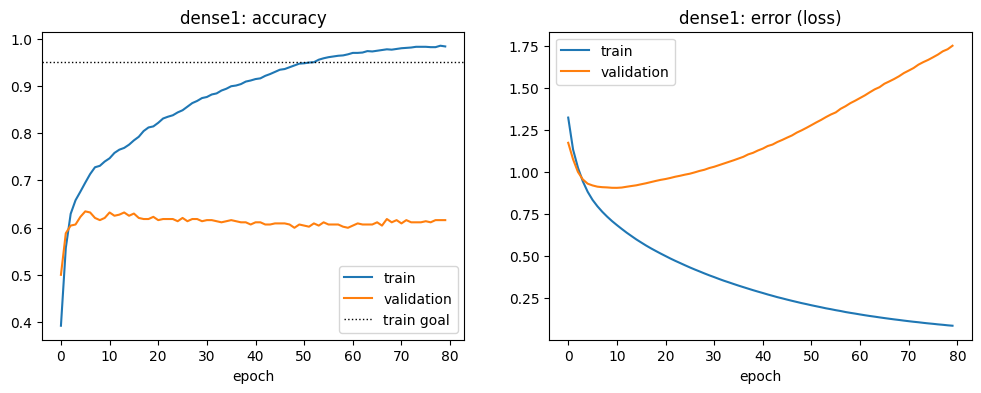

                  precision    recall  f1-score   support

    daytime_7day      0.469     0.447     0.458        85
 daytime_weekday      0.800     0.816     0.808       103
       flat_7day      0.855     0.791     0.822       187
weekday_moderate      0.427     0.530     0.473        66

        accuracy                          0.692       441
       macro avg      0.638     0.646     0.640       441
    weighted avg      0.704     0.692     0.696       441



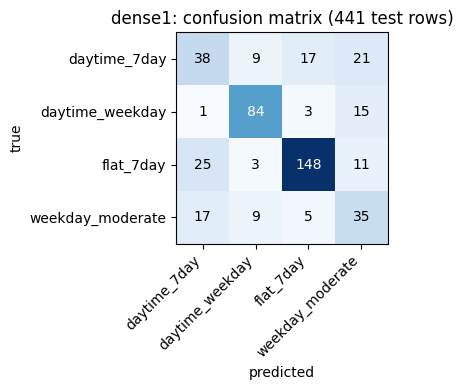

dense1: train acc 0.983 | val acc 0.616 (best 0.634) | gap +0.368 | val loss 1.749 | epochs 80 | params 8,004 | val bal acc 0.572
rule: train acc 0.983 >= goal 0.95, gap 0.368 >= 0.1 -> overfitting: regularize


In [11]:
# ===================== DENSE 1 =====================
# CHANGE FROM DENSE 0: epochs 40 -> 80 (dense0: below the training goal and still rising, see its rule line)
keras.utils.set_random_seed(SEED)
inputs = keras.Input(shape=(x_train.shape[1],))
x = layers.Dense(64, activation="relu")(inputs)
x = layers.Dense(64, activation="relu")(x)
outputs = layers.Dense(len(classes), activation="softmax")(x)
dense1 = keras.Model(inputs, outputs, name="dense1")

dense1.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
               loss="sparse_categorical_crossentropy",   # log loss (week 4), 4-class form
               metrics=["accuracy"])
dense1.summary()

h_dense1 = dense1.fit(x_train, y_train, batch_size=64, epochs=80, validation_data=(x_val, y_val),
                class_weight=class_weight, callbacks=[], verbose=0)   # verbose=2 prints every epoch
finish("dense1", 1, CHANGES["dense1"], dense1, h_dense1, parent="dense0")

---
# dense2
**Change from dense0:** 3 hidden layers (128 -> 64 -> 32), same 40 epochs. The other remedy for dense0's underfitting: more capacity instead of more epochs (week 5/6: model complexity).

Model: "dense2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 55)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │         7,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,636 (68.89 KB)

 Trainable params: 17,636 (68.89 KB)

 Non-trainable params: 0 (0.00 B)

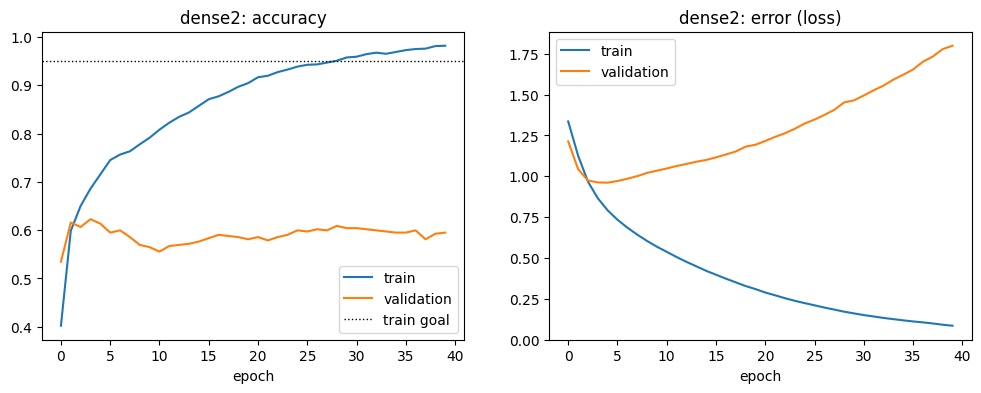

                  precision    recall  f1-score   support

    daytime_7day      0.473     0.506     0.489        85
 daytime_weekday      0.840     0.816     0.828       103
       flat_7day      0.834     0.807     0.821       187
weekday_moderate      0.435     0.455     0.444        66

        accuracy                          0.698       441
       macro avg      0.645     0.646     0.645       441
    weighted avg      0.706     0.698     0.702       441



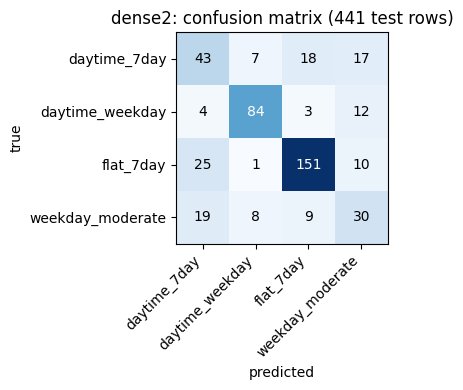

dense2: train acc 0.982 | val acc 0.595 (best 0.623) | gap +0.387 | val loss 1.799 | epochs 40 | params 17,636 | val bal acc 0.536
rule: train acc 0.982 >= goal 0.95, gap 0.387 >= 0.1 -> overfitting: regularize


In [12]:
# ===================== DENSE 2 =====================
# CHANGE FROM DENSE 0: 3 hidden layers 128 -> 64 -> 32 at the same 40 epochs (capacity route: dense0 below the training goal, see its rule line)
keras.utils.set_random_seed(SEED)
inputs = keras.Input(shape=(x_train.shape[1],))
x = layers.Dense(128, activation="relu")(inputs)
x = layers.Dense(64, activation="relu")(x)
x = layers.Dense(32, activation="relu")(x)
outputs = layers.Dense(len(classes), activation="softmax")(x)
dense2 = keras.Model(inputs, outputs, name="dense2")

dense2.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
               loss="sparse_categorical_crossentropy",   # log loss (week 4), 4-class form
               metrics=["accuracy"])
dense2.summary()

h_dense2 = dense2.fit(x_train, y_train, batch_size=64, epochs=40, validation_data=(x_val, y_val),
                class_weight=class_weight, callbacks=[], verbose=0)   # verbose=2 prints every epoch
finish("dense2", 1, CHANGES["dense2"], dense2, h_dense2, parent="dense0")

---
# dense3
**Change from dense2:** a fourth hidden layer (128 -> 128 -> 64 -> 32), same 40 epochs (second step of the capacity route).

Model: "dense3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 55)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │         7,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,148 (133.39 KB)

 Trainable params: 34,148 (133.39 KB)

 Non-trainable params: 0 (0.00 B)

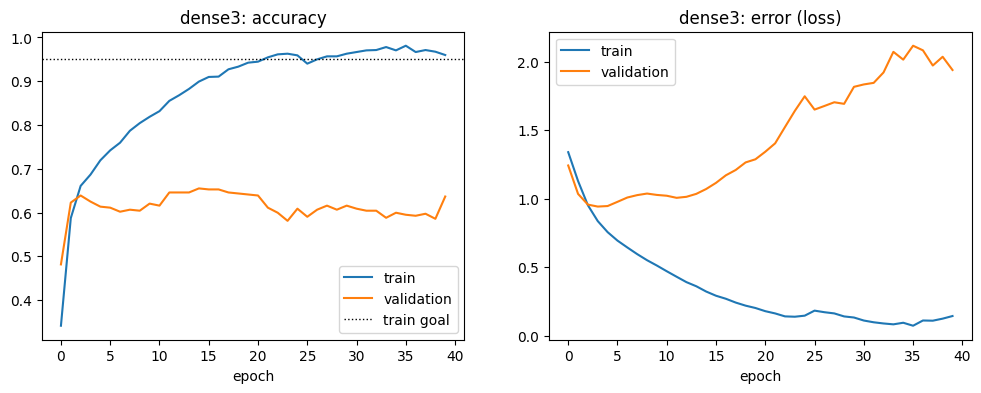

                  precision    recall  f1-score   support

    daytime_7day      0.500     0.576     0.536        85
 daytime_weekday      0.871     0.786     0.827       103
       flat_7day      0.811     0.781     0.796       187
weekday_moderate      0.471     0.500     0.485        66

        accuracy                          0.701       441
       macro avg      0.663     0.661     0.661       441
    weighted avg      0.714     0.701     0.706       441



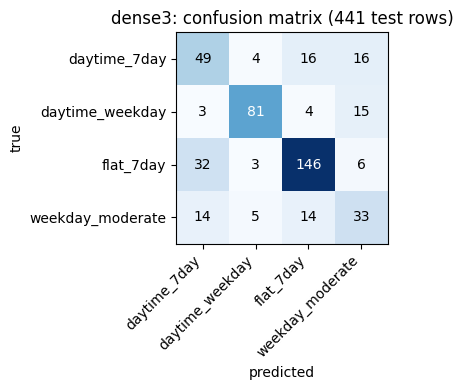

dense3: train acc 0.960 | val acc 0.637 (best 0.655) | gap +0.323 | val loss 1.941 | epochs 40 | params 34,148 | val bal acc 0.570
rule: train acc 0.960 >= goal 0.95, gap 0.323 >= 0.1 -> overfitting: regularize


In [13]:
# ===================== DENSE 3 =====================
# CHANGE FROM DENSE 2: fourth hidden layer, 128 -> 128 -> 64 -> 32, 40 epochs (capacity route, second step)
keras.utils.set_random_seed(SEED)
inputs = keras.Input(shape=(x_train.shape[1],))
x = layers.Dense(128, activation="relu")(inputs)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dense(64, activation="relu")(x)
x = layers.Dense(32, activation="relu")(x)
outputs = layers.Dense(len(classes), activation="softmax")(x)
dense3 = keras.Model(inputs, outputs, name="dense3")

dense3.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
               loss="sparse_categorical_crossentropy",   # log loss (week 4), 4-class form
               metrics=["accuracy"])
dense3.summary()

h_dense3 = dense3.fit(x_train, y_train, batch_size=64, epochs=40, validation_data=(x_val, y_val),
                class_weight=class_weight, callbacks=[], verbose=0)   # verbose=2 prints every epoch
finish("dense3", 1, CHANGES["dense3"], dense3, h_dense3, parent="dense2")

In [14]:
# Phase-2 parent rule: the phase-1 model with the highest training accuracy among those that reached TRAIN_ACC_GOAL
# (tie within 0.005 -> fewer parameters); see pick_parent in the helpers
DENSE_PARENT = PARENTS["dense"] = pick_parent("dense")

candidates (train acc, params): {'dense1': (0.983, 8004), 'dense2': (0.982, 17636), 'dense3': (0.96, 34148)}
phase-2 parent: dense1


In [15]:
# Dense phase 1 rows of the running table
block_table([n for n in runs if n.startswith("dense") and runs[n]["phase"] == 1])

,label,train_acc,val_acc,gap,epochs,val_bal_acc
dense0,"base 64-64, 40 ep",0.911,0.606,0.305,40.0,0.571
dense1,+epochs 80,0.983,0.616,0.368,80.0,0.572
dense2,3 layers 128-64-32,0.982,0.595,0.387,40.0,0.536
dense3,4 layers 128-128-64-32,0.960,0.637,0.323,40.0,0.570


## Dense phase 2: now reduce overfitting
Week 5/6 (regularization, early stopping, batch normalization, learning-rate schedules) and week 8/9 (data augmentation). The parent is the phase-1 model picked by the rule above: the highest training accuracy among those that reached `TRAIN_ACC_GOAL` ("achieve the highest accuracy you can and then do regularization"). Adam 1e-3, batch 64, the class weights and the parent's epochs stay fixed.

- **Step A, single methods:** each model adds ONE method to the parent, so each method's effect is visible on its own ("vs parent" line under each model). The models are built from the parent's spec, so the cells work for whichever parent phase 1 produced; `model.summary()` shows each architecture.
- **Step B, combining what worked:** the methods that improved validation balanced accuracy are combined one at a time, keeping each only if it helps.

The final dense model is the best model at the end of step B.

---
# dense4: +L2 1e-5
**Change from the phase-2 parent:** one method, L2 1e-5 (description printed with the model).

dense4: from dense1: L2 regularization 1e-5 on every Dense / Conv1D layer (week 5/6: start with a small value)


Model: "dense4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 55)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 64)             │         3,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,004 (31.27 KB)

 Trainable params: 8,004 (31.27 KB)

 Non-trainable params: 0 (0.00 B)

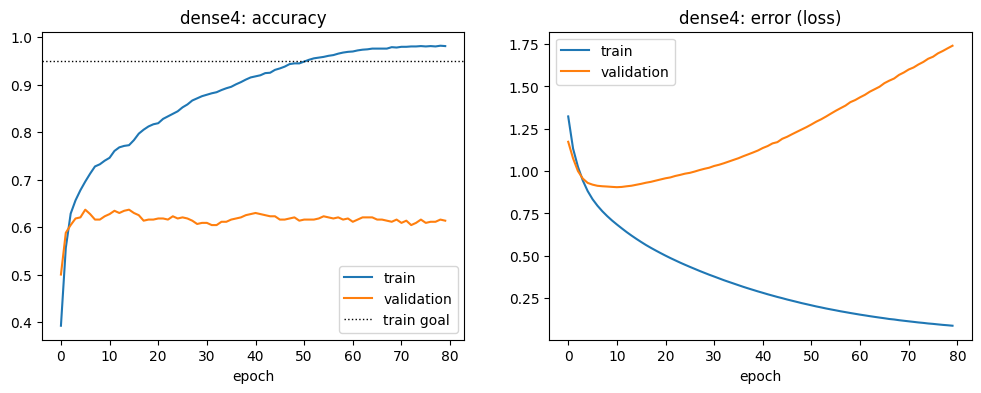

                  precision    recall  f1-score   support

    daytime_7day      0.470     0.459     0.464        85
 daytime_weekday      0.819     0.835     0.827       103
       flat_7day      0.854     0.781     0.816       187
weekday_moderate      0.415     0.515     0.459        66

        accuracy                          0.692       441
       macro avg      0.639     0.647     0.642       441
    weighted avg      0.706     0.692     0.697       441



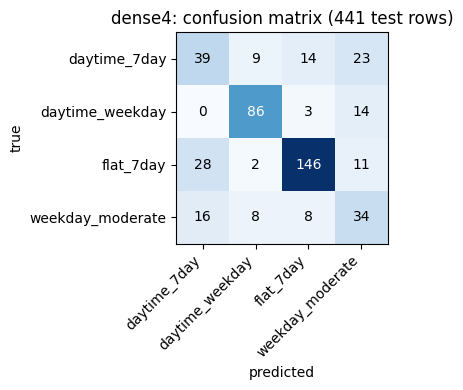

dense4: train acc 0.981 | val acc 0.613 (best 0.637) | gap +0.368 | val loss 1.741 | epochs 80 | params 8,004 | val bal acc 0.570
vs parent dense1: train acc 0.983 -> 0.981, val acc 0.616 -> 0.613, gap 0.368 -> 0.368, val bal acc 0.572 -> 0.570, val loss 1.749 -> 1.741 (regularization lowers training accuracy on purpose; judge by validation and the gap)


In [16]:
# ===================== DENSE 4: SINGLE METHOD =====================
# CHANGE FROM THE PHASE-2 PARENT: L2 1e-5 only
single("dense4", "dense", "l2_small")

---
# dense5: +L2 1e-3
**Change from the phase-2 parent:** one method, L2 1e-3 (description printed with the model).

dense5: from dense1: a stronger L2, 1e-3 (week 5/6: increase until the model generalizes better)


Model: "dense5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 55)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 64)             │         3,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,004 (31.27 KB)

 Trainable params: 8,004 (31.27 KB)

 Non-trainable params: 0 (0.00 B)

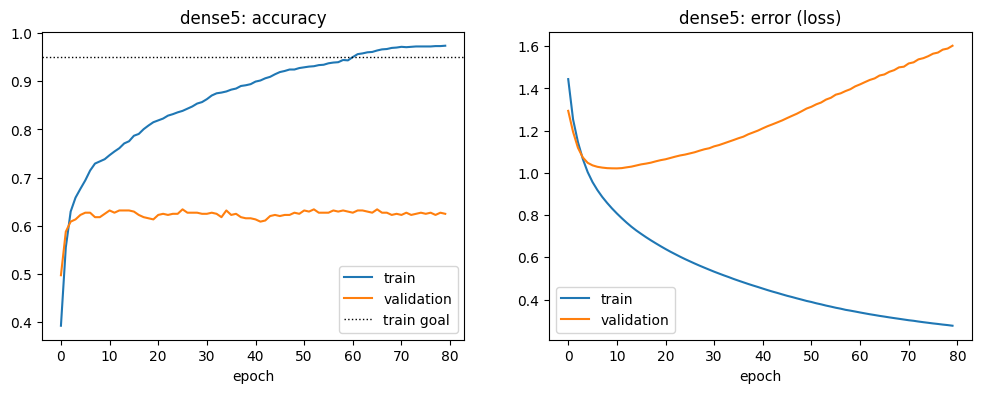

                  precision    recall  f1-score   support

    daytime_7day      0.475     0.447     0.461        85
 daytime_weekday      0.825     0.825     0.825       103
       flat_7day      0.846     0.791     0.818       187
weekday_moderate      0.398     0.500     0.443        66

        accuracy                          0.689       441
       macro avg      0.636     0.641     0.637       441
    weighted avg      0.702     0.689     0.695       441



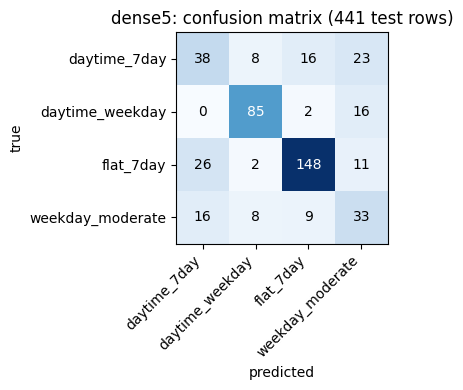

dense5: train acc 0.973 | val acc 0.625 (best 0.634) | gap +0.348 | val loss 1.603 | epochs 80 | params 8,004 | val bal acc 0.582
vs parent dense1: train acc 0.983 -> 0.973, val acc 0.616 -> 0.625, gap 0.368 -> 0.348, val bal acc 0.572 -> 0.582, val loss 1.749 -> 1.603 (regularization lowers training accuracy on purpose; judge by validation and the gap)


In [17]:
# ===================== DENSE 5: SINGLE METHOD =====================
# CHANGE FROM THE PHASE-2 PARENT: L2 1e-3 only
single("dense5", "dense", "l2_strong")

---
# dense6: +Dropout 0.3
**Change from the phase-2 parent:** one method, Dropout 0.3 (description printed with the model).

dense6: from dense1: Dropout 0.3 after each hidden layer, or after global average pooling and the Dense layer in a CNN (week 5/6: rate 0.2 to 0.5)


Model: "dense6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 55)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 64)             │         3,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,004 (31.27 KB)

 Trainable params: 8,004 (31.27 KB)

 Non-trainable params: 0 (0.00 B)

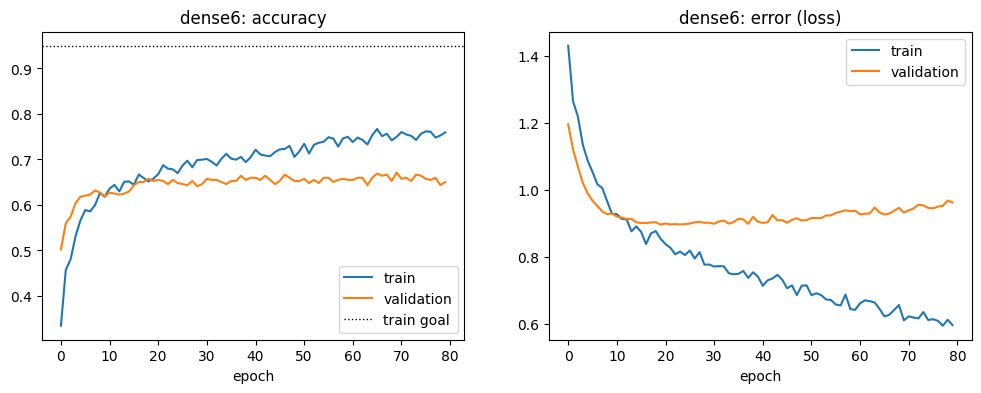

                  precision    recall  f1-score   support

    daytime_7day      0.468     0.518     0.492        85
 daytime_weekday      0.848     0.816     0.832       103
       flat_7day      0.877     0.727     0.795       187
weekday_moderate      0.419     0.591     0.491        66

        accuracy                          0.687       441
       macro avg      0.653     0.663     0.652       441
    weighted avg      0.723     0.687     0.700       441



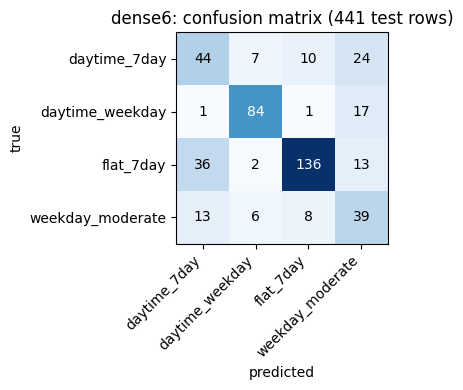

dense6: train acc 0.759 | val acc 0.650 (best 0.671) | gap +0.109 | val loss 0.963 | epochs 80 | params 8,004 | val bal acc 0.620
vs parent dense1: train acc 0.983 -> 0.759, val acc 0.616 -> 0.650, gap 0.368 -> 0.109, val bal acc 0.572 -> 0.620, val loss 1.749 -> 0.963 (regularization lowers training accuracy on purpose; judge by validation and the gap)


In [18]:
# ===================== DENSE 6: SINGLE METHOD =====================
# CHANGE FROM THE PHASE-2 PARENT: Dropout 0.3 only
single("dense6", "dense", "dropout")

---
# dense7: +early stopping
**Change from the phase-2 parent:** one method, early stopping (description printed with the model).

dense7: from dense1: early stopping on validation loss, patience 10 epochs, keep the best weights (week 5/6)


Model: "dense7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 55)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 64)             │         3,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,004 (31.27 KB)

 Trainable params: 8,004 (31.27 KB)

 Non-trainable params: 0 (0.00 B)

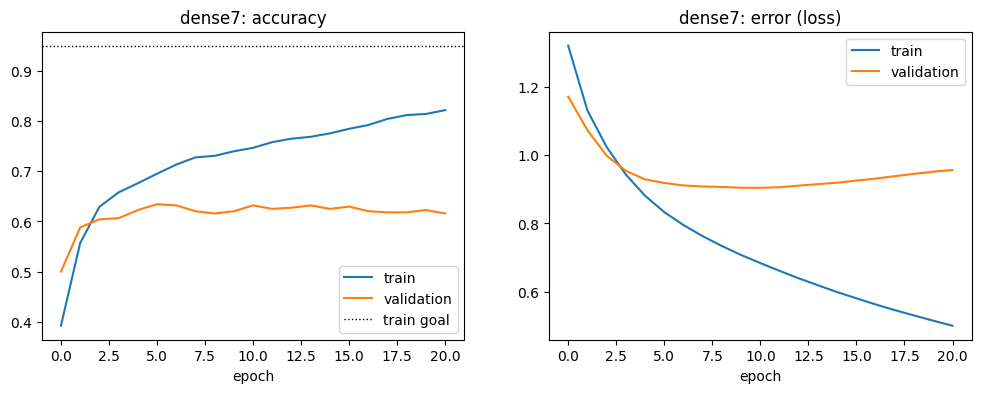

                  precision    recall  f1-score   support

    daytime_7day      0.429     0.459     0.443        85
 daytime_weekday      0.819     0.748     0.782       103
       flat_7day      0.850     0.727     0.784       187
weekday_moderate      0.406     0.591     0.481        66

        accuracy                          0.660       441
       macro avg      0.626     0.631     0.623       441
    weighted avg      0.695     0.660     0.672       441



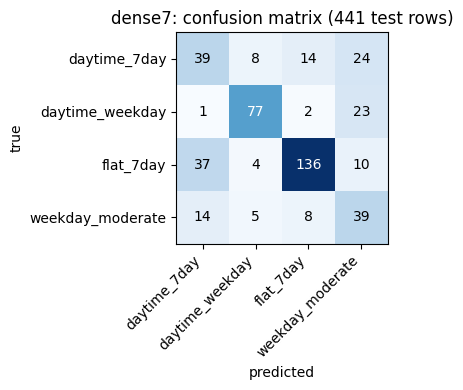

dense7: train acc 0.822 | val acc 0.616 (best 0.634) | gap +0.206 | val loss 0.957 | epochs 21 | params 8,004 | val bal acc 0.605
vs parent dense1: train acc 0.983 -> 0.822, val acc 0.616 -> 0.616, gap 0.368 -> 0.206, val bal acc 0.572 -> 0.605, val loss 1.749 -> 0.957 (regularization lowers training accuracy on purpose; judge by validation and the gap)


In [19]:
# ===================== DENSE 7: SINGLE METHOD =====================
# CHANGE FROM THE PHASE-2 PARENT: early stopping only
single("dense7", "dense", "early_stop")

---
# dense8: +BatchNorm
**Change from the phase-2 parent:** one method, BatchNorm (description printed with the model).

dense8: from dense1: BatchNormalization after each Dense / Conv1D layer (week 5/6)


Model: "dense8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)      │ (None, 55)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 64)             │         3,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_28 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_29 (Dense)                │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,516 (33.27 KB)

 Trainable params: 8,260 (32.27 KB)

 Non-trainable params: 256 (1.00 KB)

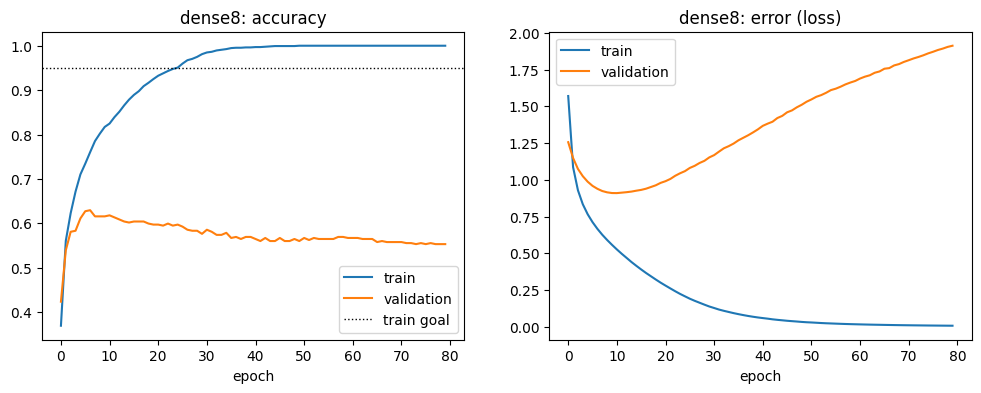

                  precision    recall  f1-score   support

    daytime_7day      0.459     0.529     0.492        85
 daytime_weekday      0.745     0.738     0.741       103
       flat_7day      0.858     0.743     0.797       187
weekday_moderate      0.405     0.485     0.441        66

        accuracy                          0.662       441
       macro avg      0.617     0.624     0.618       441
    weighted avg      0.687     0.662     0.672       441



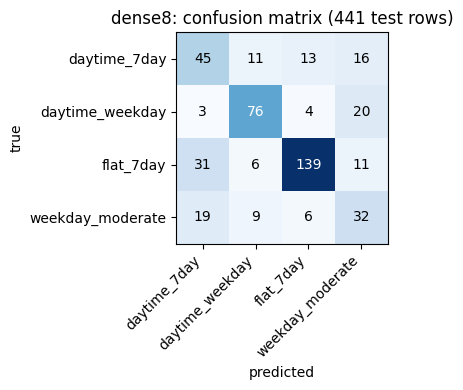

dense8: train acc 1.000 | val acc 0.553 (best 0.630) | gap +0.447 | val loss 1.912 | epochs 80 | params 8,516 | val bal acc 0.493
vs parent dense1: train acc 0.983 -> 1.000, val acc 0.616 -> 0.553, gap 0.368 -> 0.447, val bal acc 0.572 -> 0.493, val loss 1.749 -> 1.912 (regularization lowers training accuracy on purpose; judge by validation and the gap)


In [20]:
# ===================== DENSE 8: SINGLE METHOD =====================
# CHANGE FROM THE PHASE-2 PARENT: BatchNorm only
single("dense8", "dense", "batchnorm")

---
# dense9: +augmentation
**Change from the phase-2 parent:** one method, augmentation (description printed with the model).

dense9: from dense1: data augmentation (week 8/9): all 10 billing-offset copies of each training building for 1/10 of the epochs, so the number of weight updates equals the parent's


Model: "dense9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_9 (InputLayer)      │ (None, 55)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_30 (Dense)                │ (None, 64)             │         3,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,004 (31.27 KB)

 Trainable params: 8,004 (31.27 KB)

 Non-trainable params: 0 (0.00 B)

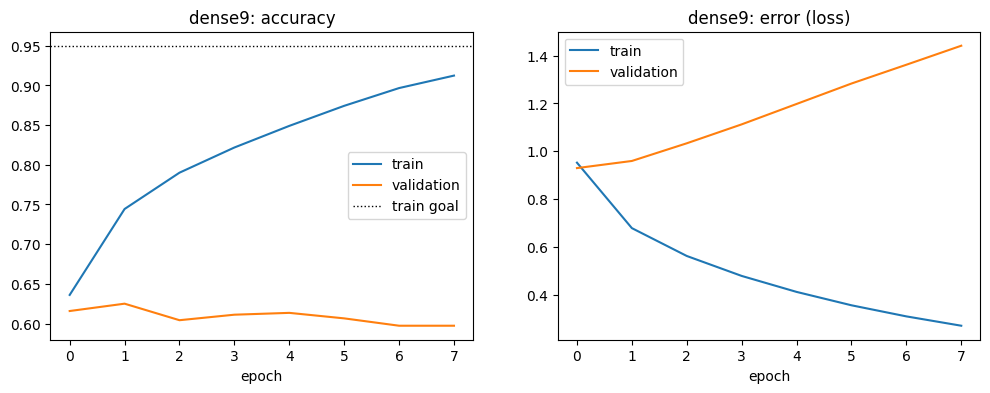

                  precision    recall  f1-score   support

    daytime_7day      0.465     0.471     0.468        85
 daytime_weekday      0.833     0.777     0.804       103
       flat_7day      0.853     0.775     0.812       187
weekday_moderate      0.393     0.530     0.452        66

        accuracy                          0.680       441
       macro avg      0.636     0.638     0.634       441
    weighted avg      0.705     0.680     0.690       441



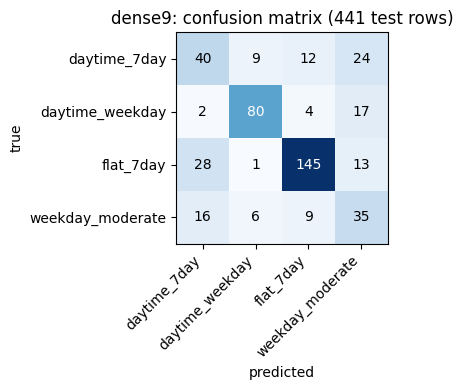

dense9: train acc 0.912 | val acc 0.597 (best 0.625) | gap +0.315 | val loss 1.442 | epochs 8 | params 8,004 | val bal acc 0.557
vs parent dense1: train acc 0.983 -> 0.912, val acc 0.616 -> 0.597, gap 0.368 -> 0.315, val bal acc 0.572 -> 0.557, val loss 1.749 -> 1.442 (regularization lowers training accuracy on purpose; judge by validation and the gap)


In [21]:
# ===================== DENSE 9: SINGLE METHOD =====================
# CHANGE FROM THE PHASE-2 PARENT: augmentation only
single("dense9", "dense", "augmentation")

---
# dense10: +step decay
**Change from the phase-2 parent:** one method, step decay (description printed with the model).

dense10: from dense1: step-decay learning rate (week 5/6): 1e-3 halved every 10 epochs


Model: "dense10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_10 (InputLayer)     │ (None, 55)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_33 (Dense)                │ (None, 64)             │         3,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_35 (Dense)                │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,004 (31.27 KB)

 Trainable params: 8,004 (31.27 KB)

 Non-trainable params: 0 (0.00 B)

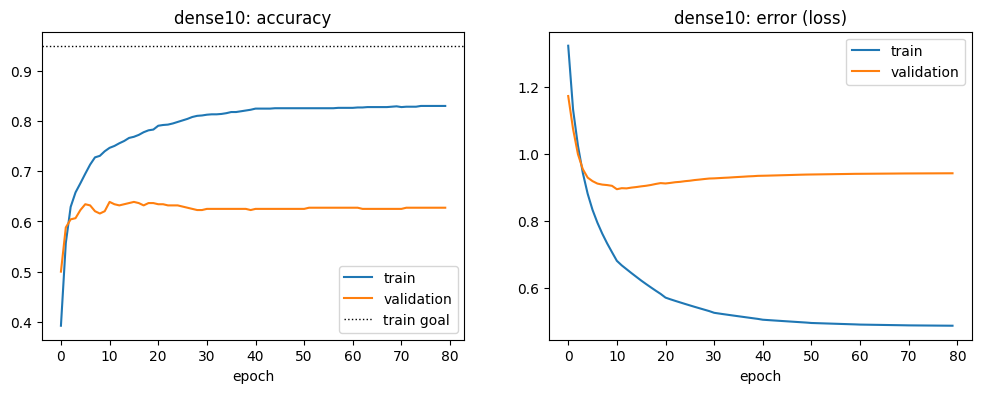

                  precision    recall  f1-score   support

    daytime_7day      0.410     0.400     0.405        85
 daytime_weekday      0.849     0.767     0.806       103
       flat_7day      0.858     0.743     0.797       187
weekday_moderate      0.369     0.576     0.450        66

        accuracy                          0.658       441
       macro avg      0.622     0.622     0.614       441
    weighted avg      0.696     0.658     0.671       441



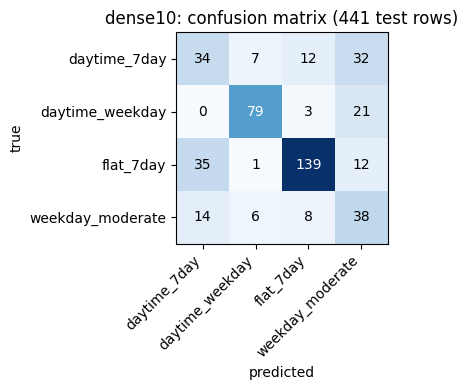

dense10: train acc 0.830 | val acc 0.627 (best 0.639) | gap +0.203 | val loss 0.942 | epochs 80 | params 8,004 | val bal acc 0.581
vs parent dense1: train acc 0.983 -> 0.830, val acc 0.616 -> 0.627, gap 0.368 -> 0.203, val bal acc 0.572 -> 0.581, val loss 1.749 -> 0.942 (regularization lowers training accuracy on purpose; judge by validation and the gap)


In [22]:
# ===================== DENSE 10: SINGLE METHOD =====================
# CHANGE FROM THE PHASE-2 PARENT: step decay only
single("dense10", "dense", "step_decay")

---
## Dense phase 2, step B: combine what worked
Iterative, validation only: start from the best single method, add the next-best improving method, keep it only if validation balanced accuracy improves, otherwise drop it and try the next (at most 4 added steps). Each trained combination is shown with its curves and test report below; the log at the end lists every step.

single methods, validation balanced accuracy change vs parent dense1 (0.572):
  Dropout       +0.048
  early stop    +0.033
  L2 1e-3       +0.011
  step decay    +0.010
  L2 1e-5       -0.002  (did not improve, not used)
  augmentation  -0.015  (did not improve, not used)
  BatchNorm     -0.079  (did not improve, not used)
start: dense6 = parent + Dropout, val bal acc 0.620

===================== DENSE_COMBO1: try adding early stop to dense6 =====================
dense_combo1: from dense1: Dropout 0.3 after each hidden layer, or after global average pooling and the Dense layer in a CNN (week 5/6: rate 0.2 to 0.5); early stopping on validation loss, patience 10 epochs, keep the best weights (week 5/6)


Model: "dense_combo1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_11 (InputLayer)     │ (None, 55)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_36 (Dense)                │ (None, 64)             │         3,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_37 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_38 (Dense)                │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,004 (31.27 KB)

 Trainable params: 8,004 (31.27 KB)

 Non-trainable params: 0 (0.00 B)

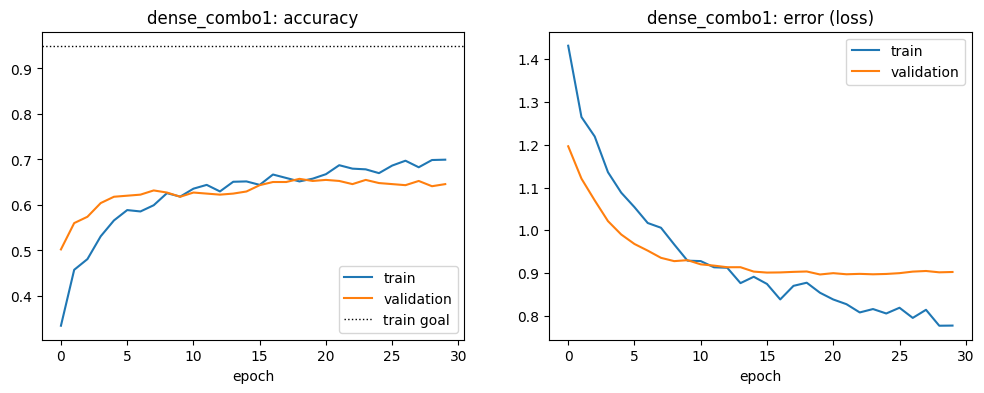

                  precision    recall  f1-score   support

    daytime_7day      0.506     0.459     0.481        85
 daytime_weekday      0.842     0.777     0.808       103
       flat_7day      0.851     0.797     0.823       187
weekday_moderate      0.468     0.667     0.550        66

        accuracy                          0.707       441
       macro avg      0.667     0.675     0.666       441
    weighted avg      0.725     0.707     0.713       441



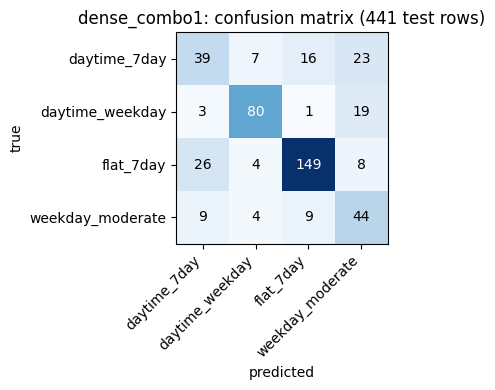

dense_combo1: train acc 0.700 | val acc 0.646 (best 0.657) | gap +0.054 | val loss 0.903 | epochs 30 | params 8,004 | val bal acc 0.618
vs parent dense1: train acc 0.983 -> 0.700, val acc 0.616 -> 0.646, gap 0.368 -> 0.054, val bal acc 0.572 -> 0.618, val loss 1.749 -> 0.903 (regularization lowers training accuracy on purpose; judge by validation and the gap)
step 1: add early stop: val bal acc 0.620 -> 0.618 -> dropped

===================== DENSE_COMBO2: try adding L2 1e-3 to dense6 =====================
dense_combo2: from dense1: Dropout 0.3 after each hidden layer, or after global average pooling and the Dense layer in a CNN (week 5/6: rate 0.2 to 0.5); a stronger L2, 1e-3 (week 5/6: increase until the model generalizes better)


Model: "dense_combo2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_12 (InputLayer)     │ (None, 55)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_39 (Dense)                │ (None, 64)             │         3,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_40 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_41 (Dense)                │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,004 (31.27 KB)

 Trainable params: 8,004 (31.27 KB)

 Non-trainable params: 0 (0.00 B)

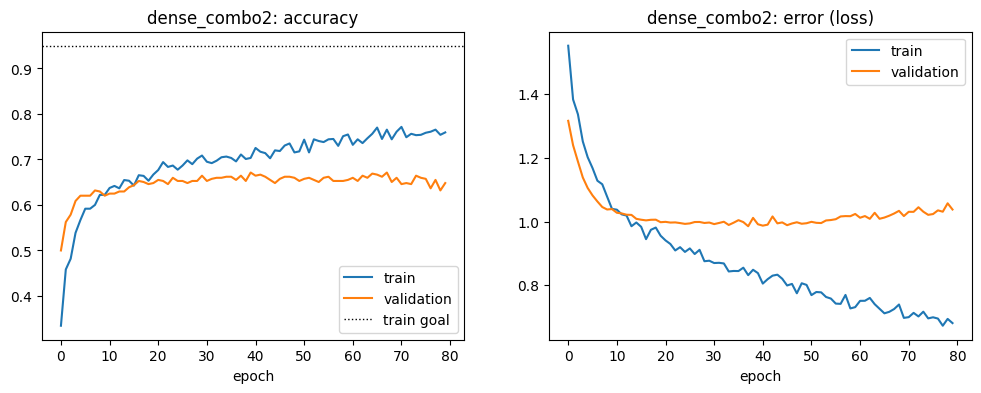

                  precision    recall  f1-score   support

    daytime_7day      0.457     0.506     0.480        85
 daytime_weekday      0.863     0.796     0.828       103
       flat_7day      0.872     0.727     0.793       187
weekday_moderate      0.406     0.591     0.481        66

        accuracy                          0.680       441
       macro avg      0.650     0.655     0.646       441
    weighted avg      0.720     0.680     0.694       441



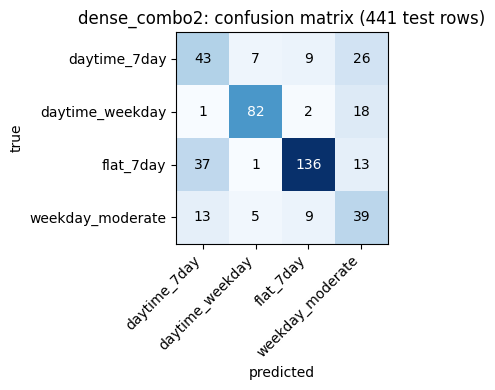

dense_combo2: train acc 0.759 | val acc 0.648 (best 0.671) | gap +0.111 | val loss 1.038 | epochs 80 | params 8,004 | val bal acc 0.617
vs parent dense1: train acc 0.983 -> 0.759, val acc 0.616 -> 0.648, gap 0.368 -> 0.111, val bal acc 0.572 -> 0.617, val loss 1.749 -> 1.038 (regularization lowers training accuracy on purpose; judge by validation and the gap)
step 2: add L2 1e-3: val bal acc 0.620 -> 0.617 -> dropped

===================== DENSE_COMBO3: try adding step decay to dense6 =====================
dense_combo3: from dense1: Dropout 0.3 after each hidden layer, or after global average pooling and the Dense layer in a CNN (week 5/6: rate 0.2 to 0.5); step-decay learning rate (week 5/6): 1e-3 halved every 10 epochs


Model: "dense_combo3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_13 (InputLayer)     │ (None, 55)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_42 (Dense)                │ (None, 64)             │         3,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_43 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_44 (Dense)                │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,004 (31.27 KB)

 Trainable params: 8,004 (31.27 KB)

 Non-trainable params: 0 (0.00 B)

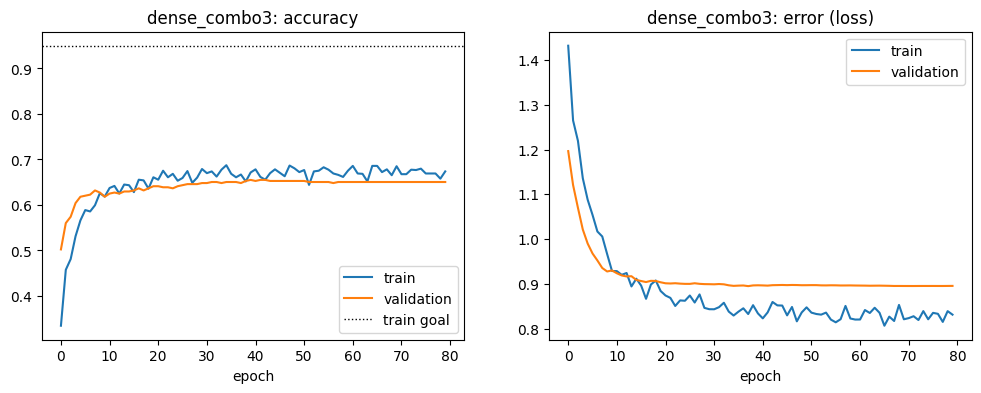

                  precision    recall  f1-score   support

    daytime_7day      0.513     0.471     0.491        85
 daytime_weekday      0.849     0.767     0.806       103
       flat_7day      0.851     0.797     0.823       187
weekday_moderate      0.463     0.667     0.547        66

        accuracy                          0.707       441
       macro avg      0.669     0.675     0.667       441
    weighted avg      0.728     0.707     0.714       441



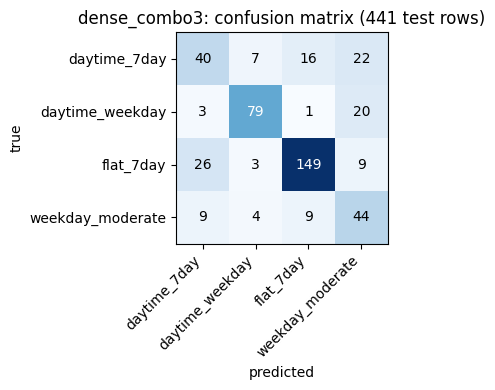

dense_combo3: train acc 0.674 | val acc 0.650 (best 0.655) | gap +0.023 | val loss 0.896 | epochs 80 | params 8,004 | val bal acc 0.618
vs parent dense1: train acc 0.983 -> 0.674, val acc 0.616 -> 0.650, gap 0.368 -> 0.023, val bal acc 0.572 -> 0.618, val loss 1.749 -> 0.896 (regularization lowers training accuracy on purpose; judge by validation and the gap)
step 3: add step decay: val bal acc 0.620 -> 0.618 -> dropped

best dense model after the loop: dense6 (Dropout)


,step,model,added,methods,val_bal_acc_before,val_bal_acc_after,kept
0,1,dense_combo1,early stop,Dropout + early stop,0.62,0.618,False
1,2,dense_combo2,L2 1e-3,Dropout + L2 1e-3,0.62,0.617,False
2,3,dense_combo3,step decay,Dropout + step decay,0.62,0.618,False


In [23]:
FINAL_DENSE, dense_combo_log = combine("dense")
with pd.option_context("display.max_colwidth", None, "display.max_columns", None, "display.width", 250):
    display(dense_combo_log)

In [24]:
# Dense phase 2 rows of the running table, with the change against the parent
print("final dense model (best after the combination loop):", FINAL_DENSE)
block_table([n for n in runs if n.startswith("dense") and runs[n]["phase"] == 2])

final dense model (best after the combination loop): dense6


,label,train_acc,val_acc,gap,epochs,val_bal_acc,parent,val_bal_acc_vs_parent,gap_vs_parent
dense4,+L2 1e-5,0.981,0.613,0.368,80.0,0.570,dense1,-0.002,0.000
dense5,+L2 1e-3,0.973,0.625,0.348,80.0,0.582,dense1,0.011,-0.019
dense6,+Dropout 0.3,0.759,0.650,0.109,80.0,0.620,dense1,0.048,-0.259
dense7,+early stopping,0.822,0.616,0.206,21.0,0.605,dense1,0.033,-0.162
dense8,+BatchNorm,1.000,0.553,0.447,80.0,0.493,dense1,-0.079,0.079
dense9,+augmentation,0.912,0.597,0.315,8.0,0.557,dense1,-0.015,-0.052
dense10,+step decay,0.830,0.627,0.203,80.0,0.581,dense1,0.010,-0.165
dense_combo1,combo: Dropout + early stop,0.700,0.646,0.054,30.0,0.618,dense1,0.046,-0.314
dense_combo2,combo: Dropout + L2 1e-3,0.759,0.648,0.111,80.0,0.617,dense1,0.045,-0.256
dense_combo3,combo: Dropout + step decay,0.674,0.650,0.023,80.0,0.618,dense1,0.046,-0.344


---
# 2. 1-D CNNs on the 12-month sequence
The 12 bills are a sequence in time, so a 1-D convolution can look for patterns across neighboring months: a small filter (kernel) slides along the year and builds a feature map (week 4, convolutional layer). Pooling layers summarize each region and make the net less sensitive to exactly where a feature sits (week 4, max pooling). Global average pooling takes the average of each feature map (week 8/9, GoogleNet).

- **Input A** = the sequence, shape (12 months, 2 channels): monthly kWh share and monthly relative peak.
- **Input B** = every other feature (monthly load factor, size, latitude, hourly flag, building type and region columns).

Fixed for every CNN: kernel 3, ReLU, Adam 1e-3, batch 64, the same class weights.

## CNN phase 1: fit the training data first
Same rules as dense phase 1 (weeks 2, 3, 5/6): no Dropout, no L2, no BatchNormalization, no early stopping, no schedule, un-augmented rows. Start from one conv layer; when training accuracy is still rising train longer, when it is flat and below the goal add conv layers with more filters (week 8/9: LeNet stacks conv + pooling layers; deeper models capture more complex patterns).

---
# cnn0
**Change from base:** none: base CNN, one Conv1D layer (32 filters, kernel 3) -> MaxPool -> global average pooling -> join metadata -> Dense 64 -> softmax, 40 epochs, no regularization.

Model: "cnn0"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ monthly_sequence    │ (None, 12, 2)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 12, 32)    │        224 │ monthly_sequence… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 6, 32)     │          0 │ conv1d[0][0]      │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 32)        │          0 │ max_pooling1d[0]… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ other_features      │ (None, 31)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 63)        │          0 │ global_average_p… │
│ (Concatenate)       │                   │            │ other_features[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_45 (Dense)    │ (None, 64)        │      4,096 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_46 (Dense)    │ (None, 4)         │        260 │ dense_45[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,580 (17.89 KB)

 Trainable params: 4,580 (17.89 KB)

 Non-trainable params: 0 (0.00 B)

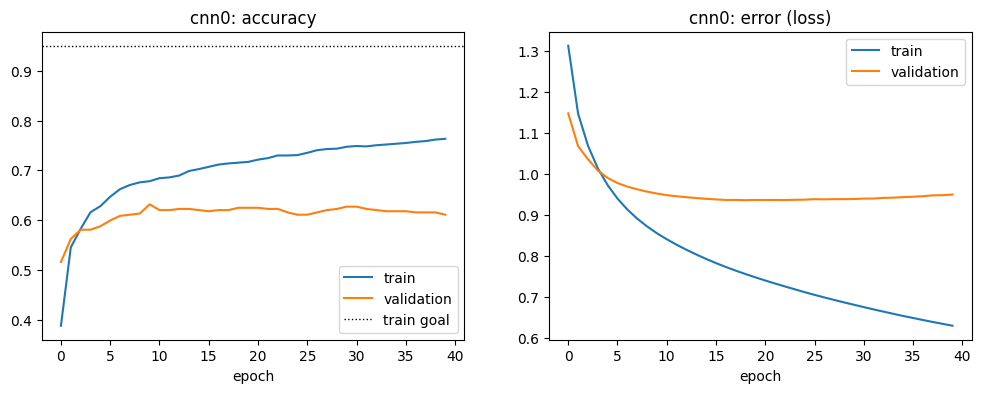

                  precision    recall  f1-score   support

    daytime_7day      0.433     0.494     0.462        85
 daytime_weekday      0.879     0.777     0.825       103
       flat_7day      0.862     0.733     0.792       187
weekday_moderate      0.426     0.606     0.500        66

        accuracy                          0.678       441
       macro avg      0.650     0.652     0.645       441
    weighted avg      0.718     0.678     0.692       441



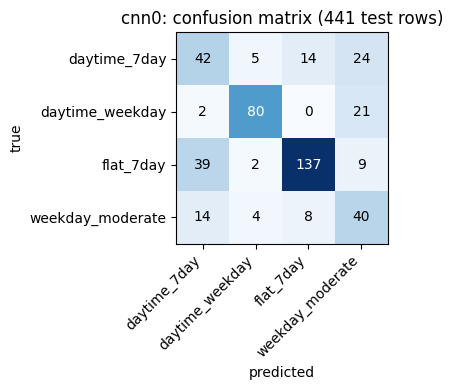

cnn0: train acc 0.763 | val acc 0.611 (best 0.632) | gap +0.152 | val loss 0.950 | epochs 40 | params 4,580 | val bal acc 0.576
rule: train acc 0.763 < goal 0.95, flat (+0.009 over the last 5 epochs) -> underfitting: add capacity (more layers or units)


In [25]:
# ===================== CNN 0 (BASE) =====================
# Base CNN: one conv layer (week 4: convolutional + pooling layers), global average pooling (week 8/9, GoogleNet)
keras.utils.set_random_seed(SEED)
in_seq  = keras.Input(shape=(12, 2), name="monthly_sequence")
in_rest = keras.Input(shape=(len(rest_cols),), name="other_features")
x = in_seq
x = layers.Conv1D(32, kernel_size=3, padding="same", activation="relu")(x)
x = layers.MaxPooling1D(pool_size=2)(x)
x = layers.GlobalAveragePooling1D()(x)
x = layers.concatenate([x, in_rest])          # join the sequence summary with the metadata
x = layers.Dense(64, activation="relu")(x)
outputs = layers.Dense(len(classes), activation="softmax")(x)
cnn0 = keras.Model([in_seq, in_rest], outputs, name="cnn0")

cnn0.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
             loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cnn0.summary()

h_cnn0 = cnn0.fit([seq_train, rest_train], y_train, batch_size=64, epochs=40, validation_data=([seq_val, rest_val], y_val),
              class_weight=class_weight, callbacks=[], verbose=0)   # verbose=2 prints every epoch
finish("cnn0", 1, CHANGES["cnn0"], cnn0, h_cnn0, xv=[seq_val, rest_val], xt=[seq_test, rest_test])

---
# cnn1
**Change from cnn0:** epochs 40 -> 100 (week 3: epochs). cnn0 ended below the training goal. Its rule line reads flat (+0.009 over the last 5 epochs, just under the 0.01 cut-off), which points to more capacity; more epochs is the cheaper change, so it is tried first.

Model: "cnn1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ monthly_sequence    │ (None, 12, 2)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 12, 32)    │        224 │ monthly_sequence… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_1     │ (None, 6, 32)     │          0 │ conv1d_1[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 32)        │          0 │ max_pooling1d_1[… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ other_features      │ (None, 31)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 63)        │          0 │ global_average_p… │
│ (Concatenate)       │                   │            │ other_features[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_47 (Dense)    │ (None, 64)        │      4,096 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_48 (Dense)    │ (None, 4)         │        260 │ dense_47[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,580 (17.89 KB)

 Trainable params: 4,580 (17.89 KB)

 Non-trainable params: 0 (0.00 B)

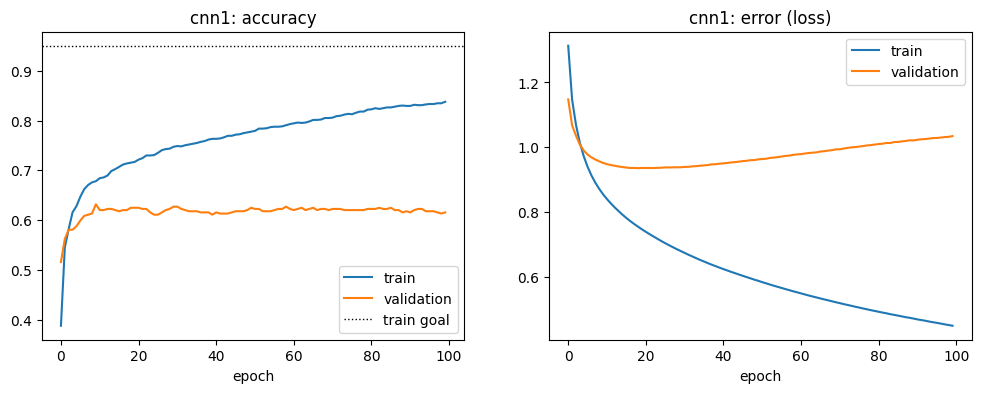

                  precision    recall  f1-score   support

    daytime_7day      0.443     0.506     0.473        85
 daytime_weekday      0.840     0.816     0.828       103
       flat_7day      0.877     0.765     0.817       187
weekday_moderate      0.420     0.515     0.463        66

        accuracy                          0.689       441
       macro avg      0.645     0.650     0.645       441
    weighted avg      0.716     0.689     0.700       441



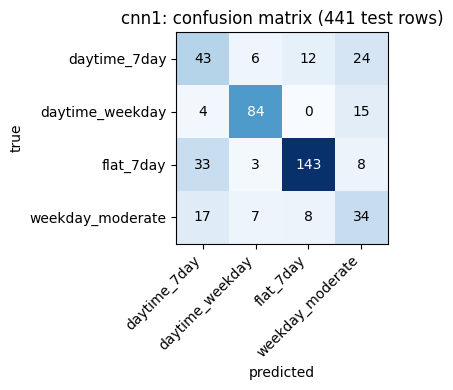

cnn1: train acc 0.838 | val acc 0.616 (best 0.632) | gap +0.222 | val loss 1.035 | epochs 100 | params 4,580 | val bal acc 0.578
rule: train acc 0.838 < goal 0.95, flat (+0.004 over the last 5 epochs) -> underfitting: add capacity (more layers or units)


In [26]:
# ===================== CNN 1 =====================
# CHANGE FROM CNN 0: epochs 40 -> 100 (cnn0: below the training goal; its rule line reads flat, epochs tried first as the cheaper change)
keras.utils.set_random_seed(SEED)
in_seq  = keras.Input(shape=(12, 2), name="monthly_sequence")
in_rest = keras.Input(shape=(len(rest_cols),), name="other_features")
x = in_seq
x = layers.Conv1D(32, kernel_size=3, padding="same", activation="relu")(x)
x = layers.MaxPooling1D(pool_size=2)(x)
x = layers.GlobalAveragePooling1D()(x)
x = layers.concatenate([x, in_rest])          # join the sequence summary with the metadata
x = layers.Dense(64, activation="relu")(x)
outputs = layers.Dense(len(classes), activation="softmax")(x)
cnn1 = keras.Model([in_seq, in_rest], outputs, name="cnn1")

cnn1.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
             loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cnn1.summary()

h_cnn1 = cnn1.fit([seq_train, rest_train], y_train, batch_size=64, epochs=100, validation_data=([seq_val, rest_val], y_val),
              class_weight=class_weight, callbacks=[], verbose=0)   # verbose=2 prints every epoch
finish("cnn1", 1, CHANGES["cnn1"], cnn1, h_cnn1, xv=[seq_val, rest_val], xt=[seq_test, rest_test], parent="cnn0")

---
# cnn2
**Change from cnn1:** a second conv layer with more filters (32 -> 64). cnn1 ended below the training goal and flat, so more capacity (week 5/6; week 8/9 LeNet: 2 conv + 2 pool).

Model: "cnn2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ monthly_sequence    │ (None, 12, 2)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 12, 32)    │        224 │ monthly_sequence… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_2     │ (None, 6, 32)     │          0 │ conv1d_2[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 6, 64)     │      6,208 │ max_pooling1d_2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_3     │ (None, 3, 64)     │          0 │ conv1d_3[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ max_pooling1d_3[… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ other_features      │ (None, 31)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 95)        │          0 │ global_average_p… │
│ (Concatenate)       │                   │            │ other_features[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_49 (Dense)    │ (None, 64)        │      6,144 │ concatenate_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_50 (Dense)    │ (None, 4)         │        260 │ dense_49[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 12,836 (50.14 KB)

 Trainable params: 12,836 (50.14 KB)

 Non-trainable params: 0 (0.00 B)

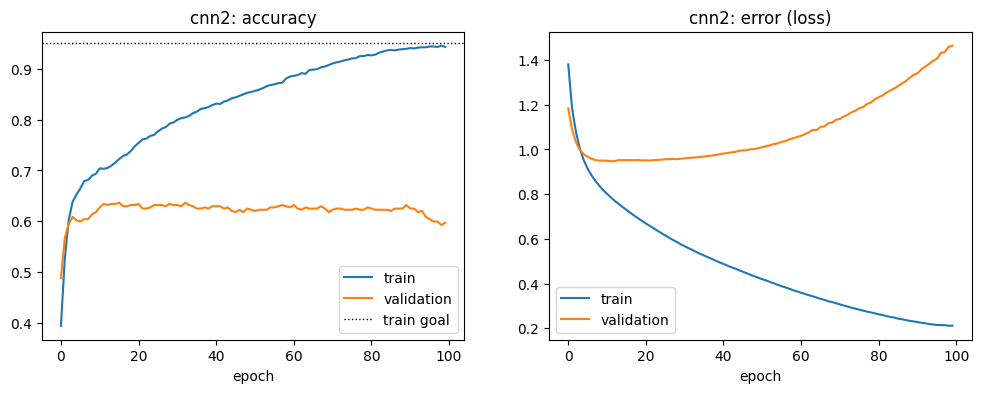

                  precision    recall  f1-score   support

    daytime_7day      0.457     0.682     0.547        85
 daytime_weekday      0.879     0.845     0.861       103
       flat_7day      0.848     0.807     0.827       187
weekday_moderate      0.595     0.333     0.427        66

        accuracy                          0.721       441
       macro avg      0.695     0.667     0.666       441
    weighted avg      0.742     0.721     0.721       441



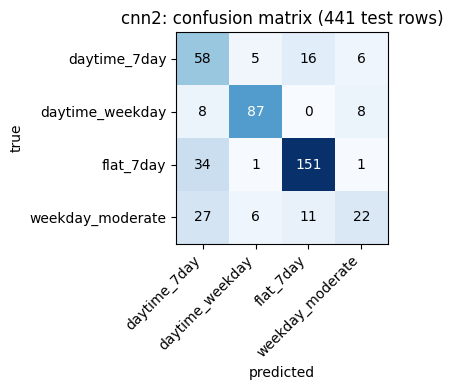

cnn2: train acc 0.943 | val acc 0.597 (best 0.637) | gap +0.346 | val loss 1.464 | epochs 100 | params 12,836 | val bal acc 0.541
rule: train acc 0.943 < goal 0.95, flat (+0.002 over the last 5 epochs) -> underfitting: add capacity (more layers or units)


In [27]:
# ===================== CNN 2 =====================
# CHANGE FROM CNN 1: second conv layer, 64 filters (cnn1: below the training goal and flat, see its rule line -> add capacity)
keras.utils.set_random_seed(SEED)
in_seq  = keras.Input(shape=(12, 2), name="monthly_sequence")
in_rest = keras.Input(shape=(len(rest_cols),), name="other_features")
x = in_seq
x = layers.Conv1D(32, kernel_size=3, padding="same", activation="relu")(x)
x = layers.MaxPooling1D(pool_size=2)(x)
x = layers.Conv1D(64, kernel_size=3, padding="same", activation="relu")(x)
x = layers.MaxPooling1D(pool_size=2)(x)
x = layers.GlobalAveragePooling1D()(x)
x = layers.concatenate([x, in_rest])          # join the sequence summary with the metadata
x = layers.Dense(64, activation="relu")(x)
outputs = layers.Dense(len(classes), activation="softmax")(x)
cnn2 = keras.Model([in_seq, in_rest], outputs, name="cnn2")

cnn2.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
             loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cnn2.summary()

h_cnn2 = cnn2.fit([seq_train, rest_train], y_train, batch_size=64, epochs=100, validation_data=([seq_val, rest_val], y_val),
              class_weight=class_weight, callbacks=[], verbose=0)   # verbose=2 prints every epoch
finish("cnn2", 1, CHANGES["cnn2"], cnn2, h_cnn2, xv=[seq_val, rest_val], xt=[seq_test, rest_test], parent="cnn1")

---
# cnn3
**Change from cnn2:** a third conv layer with more filters (32 -> 64 -> 128). cnn2 still below the goal and flat.

Model: "cnn3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ monthly_sequence    │ (None, 12, 2)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 12, 32)    │        224 │ monthly_sequence… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_4     │ (None, 6, 32)     │          0 │ conv1d_4[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 6, 64)     │      6,208 │ max_pooling1d_4[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_5     │ (None, 3, 64)     │          0 │ conv1d_5[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_6 (Conv1D)   │ (None, 3, 128)    │     24,704 │ max_pooling1d_5[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_6     │ (None, 1, 128)    │          0 │ conv1d_6[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ max_pooling1d_6[… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ other_features      │ (None, 31)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_3       │ (None, 159)       │          0 │ global_average_p… │
│ (Concatenate)       │                   │            │ other_features[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_51 (Dense)    │ (None, 64)        │     10,240 │ concatenate_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_52 (Dense)    │ (None, 4)         │        260 │ dense_51[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 41,636 (162.64 KB)

 Trainable params: 41,636 (162.64 KB)

 Non-trainable params: 0 (0.00 B)

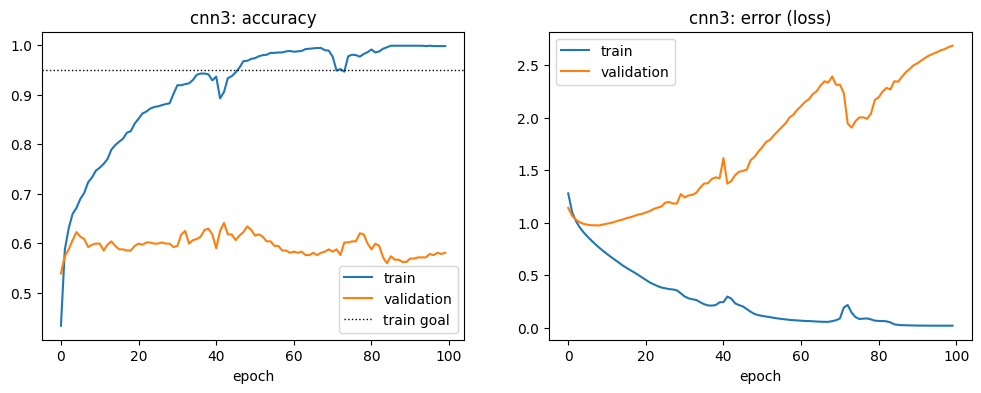

                  precision    recall  f1-score   support

    daytime_7day      0.448     0.306     0.364        85
 daytime_weekday      0.792     0.777     0.784       103
       flat_7day      0.759     0.824     0.790       187
weekday_moderate      0.392     0.470     0.428        66

        accuracy                          0.660       441
       macro avg      0.598     0.594     0.591       441
    weighted avg      0.652     0.660     0.652       441



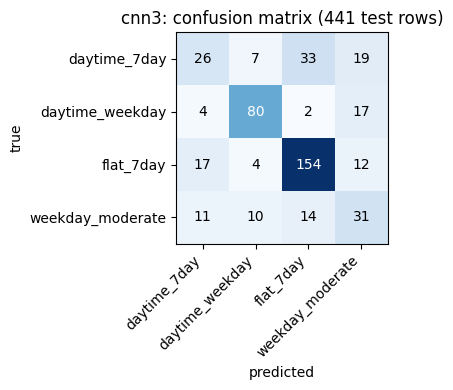

cnn3: train acc 0.998 | val acc 0.581 (best 0.641) | gap +0.417 | val loss 2.686 | epochs 100 | params 41,636 | val bal acc 0.511
rule: train acc 0.998 >= goal 0.95, gap 0.417 >= 0.1 -> overfitting: regularize


In [28]:
# ===================== CNN 3 =====================
# CHANGE FROM CNN 2: third conv layer, 128 filters (cnn2: see its rule line -> add capacity)
keras.utils.set_random_seed(SEED)
in_seq  = keras.Input(shape=(12, 2), name="monthly_sequence")
in_rest = keras.Input(shape=(len(rest_cols),), name="other_features")
x = in_seq
x = layers.Conv1D(32, kernel_size=3, padding="same", activation="relu")(x)
x = layers.MaxPooling1D(pool_size=2)(x)
x = layers.Conv1D(64, kernel_size=3, padding="same", activation="relu")(x)
x = layers.MaxPooling1D(pool_size=2)(x)
x = layers.Conv1D(128, kernel_size=3, padding="same", activation="relu")(x)
x = layers.MaxPooling1D(pool_size=2)(x)
x = layers.GlobalAveragePooling1D()(x)
x = layers.concatenate([x, in_rest])          # join the sequence summary with the metadata
x = layers.Dense(64, activation="relu")(x)
outputs = layers.Dense(len(classes), activation="softmax")(x)
cnn3 = keras.Model([in_seq, in_rest], outputs, name="cnn3")

cnn3.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
             loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cnn3.summary()

h_cnn3 = cnn3.fit([seq_train, rest_train], y_train, batch_size=64, epochs=100, validation_data=([seq_val, rest_val], y_val),
              class_weight=class_weight, callbacks=[], verbose=0)   # verbose=2 prints every epoch
finish("cnn3", 1, CHANGES["cnn3"], cnn3, h_cnn3, xv=[seq_val, rest_val], xt=[seq_test, rest_test], parent="cnn2")

In [29]:
# Phase-2 parent rule (same as for the dense nets): highest training accuracy among the phase-1 CNNs that reached TRAIN_ACC_GOAL
CNN_PARENT = PARENTS["cnn"] = pick_parent("cnn")

candidates (train acc, params): {'cnn3': (0.998, 41636)}
phase-2 parent: cnn3


In [30]:
# CNN phase 1 rows of the running table
block_table([n for n in runs if n.startswith("cnn") and runs[n]["phase"] == 1])

,label,train_acc,val_acc,gap,epochs,val_bal_acc
cnn0,"base 1 conv, 40 ep",0.763,0.611,0.152,40.0,0.576
cnn1,+epochs 100,0.838,0.616,0.222,100.0,0.578
cnn2,+conv layer (64),0.943,0.597,0.346,100.0,0.541
cnn3,+conv layer (128),0.998,0.581,0.417,100.0,0.511


## CNN phase 2: now reduce overfitting
Week 5/6 (regularization, early stopping, batch normalization, learning-rate schedules) and week 8/9 (data augmentation). The parent is the phase-1 model picked by the rule above: the highest training accuracy among those that reached `TRAIN_ACC_GOAL` ("achieve the highest accuracy you can and then do regularization"). Adam 1e-3, batch 64, the class weights and the parent's epochs stay fixed.

- **Step A, single methods:** each model adds ONE method to the parent, so each method's effect is visible on its own ("vs parent" line under each model). The models are built from the parent's spec, so the cells work for whichever parent phase 1 produced; `model.summary()` shows each architecture.
- **Step B, combining what worked:** the methods that improved validation balanced accuracy are combined one at a time, keeping each only if it helps.

The final CNN is the best model at the end of step B.

---
# cnn4: +L2 1e-5
**Change from the phase-2 parent:** one method, L2 1e-5 (description printed with the model).

cnn4: from cnn3: L2 regularization 1e-5 on every Dense / Conv1D layer (week 5/6: start with a small value)


Model: "cnn4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ monthly_sequence    │ (None, 12, 2)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_7 (Conv1D)   │ (None, 12, 32)    │        224 │ monthly_sequence… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_7     │ (None, 6, 32)     │          0 │ conv1d_7[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_8 (Conv1D)   │ (None, 6, 64)     │      6,208 │ max_pooling1d_7[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_8     │ (None, 3, 64)     │          0 │ conv1d_8[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_9 (Conv1D)   │ (None, 3, 128)    │     24,704 │ max_pooling1d_8[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_9     │ (None, 1, 128)    │          0 │ conv1d_9[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ max_pooling1d_9[… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ other_features      │ (None, 31)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_4       │ (None, 159)       │          0 │ global_average_p… │
│ (Concatenate)       │                   │            │ other_features[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_53 (Dense)    │ (None, 64)        │     10,240 │ concatenate_4[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_54 (Dense)    │ (None, 4)         │        260 │ dense_53[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 41,636 (162.64 KB)

 Trainable params: 41,636 (162.64 KB)

 Non-trainable params: 0 (0.00 B)

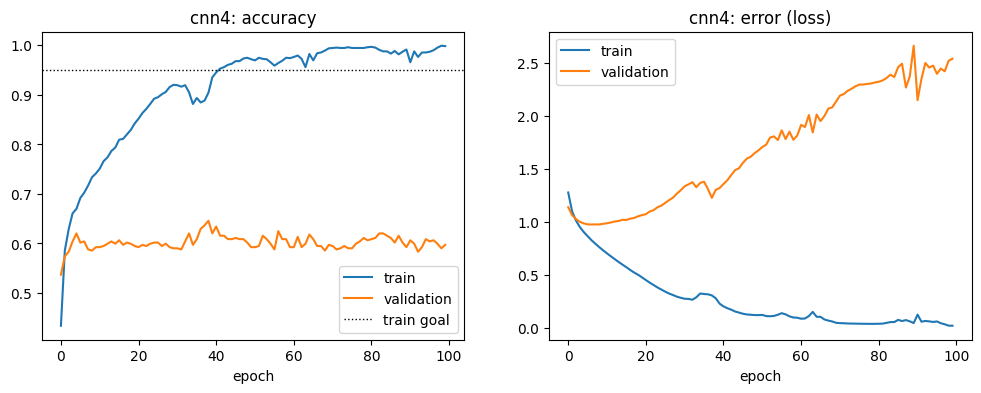

                  precision    recall  f1-score   support

    daytime_7day      0.489     0.259     0.338        85
 daytime_weekday      0.806     0.806     0.806       103
       flat_7day      0.762     0.840     0.799       187
weekday_moderate      0.414     0.545     0.471        66

        accuracy                          0.676       441
       macro avg      0.618     0.612     0.603       441
    weighted avg      0.668     0.676     0.663       441



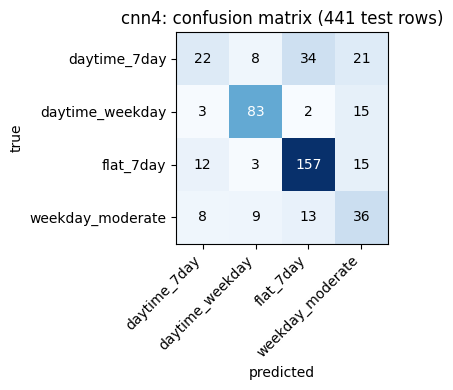

cnn4: train acc 0.998 | val acc 0.597 (best 0.646) | gap +0.401 | val loss 2.543 | epochs 100 | params 41,636 | val bal acc 0.531
vs parent cnn3: train acc 0.998 -> 0.998, val acc 0.581 -> 0.597, gap 0.417 -> 0.401, val bal acc 0.511 -> 0.531, val loss 2.686 -> 2.543 (regularization lowers training accuracy on purpose; judge by validation and the gap)


In [31]:
# ===================== CNN 4: SINGLE METHOD =====================
# CHANGE FROM THE PHASE-2 PARENT: L2 1e-5 only
single("cnn4", "cnn", "l2_small")

---
# cnn5: +L2 1e-3
**Change from the phase-2 parent:** one method, L2 1e-3 (description printed with the model).

cnn5: from cnn3: a stronger L2, 1e-3 (week 5/6: increase until the model generalizes better)


Model: "cnn5"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ monthly_sequence    │ (None, 12, 2)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_10 (Conv1D)  │ (None, 12, 32)    │        224 │ monthly_sequence… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_10    │ (None, 6, 32)     │          0 │ conv1d_10[0][0]   │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_11 (Conv1D)  │ (None, 6, 64)     │      6,208 │ max_pooling1d_10… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_11    │ (None, 3, 64)     │          0 │ conv1d_11[0][0]   │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_12 (Conv1D)  │ (None, 3, 128)    │     24,704 │ max_pooling1d_11… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_12    │ (None, 1, 128)    │          0 │ conv1d_12[0][0]   │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ max_pooling1d_12… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ other_features      │ (None, 31)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_5       │ (None, 159)       │          0 │ global_average_p… │
│ (Concatenate)       │                   │            │ other_features[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_55 (Dense)    │ (None, 64)        │     10,240 │ concatenate_5[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_56 (Dense)    │ (None, 4)         │        260 │ dense_55[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 41,636 (162.64 KB)

 Trainable params: 41,636 (162.64 KB)

 Non-trainable params: 0 (0.00 B)

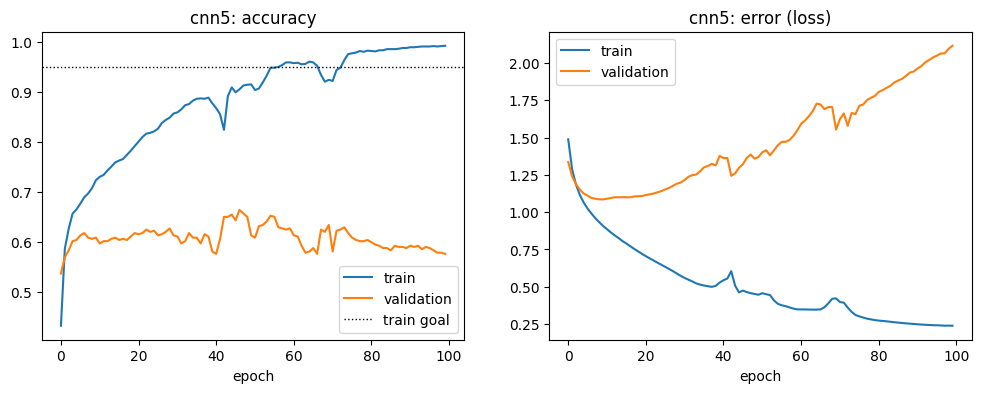

                  precision    recall  f1-score   support

    daytime_7day      0.441     0.529     0.481        85
 daytime_weekday      0.820     0.796     0.808       103
       flat_7day      0.820     0.733     0.774       187
weekday_moderate      0.403     0.439     0.420        66

        accuracy                          0.664       441
       macro avg      0.621     0.624     0.621       441
    weighted avg      0.685     0.664     0.673       441



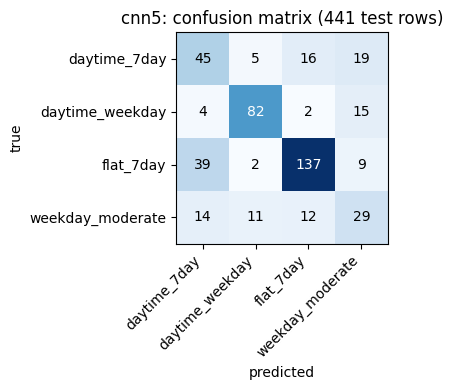

cnn5: train acc 0.993 | val acc 0.576 (best 0.664) | gap +0.417 | val loss 2.115 | epochs 100 | params 41,636 | val bal acc 0.528
vs parent cnn3: train acc 0.998 -> 0.993, val acc 0.581 -> 0.576, gap 0.417 -> 0.417, val bal acc 0.511 -> 0.528, val loss 2.686 -> 2.115 (regularization lowers training accuracy on purpose; judge by validation and the gap)


In [32]:
# ===================== CNN 5: SINGLE METHOD =====================
# CHANGE FROM THE PHASE-2 PARENT: L2 1e-3 only
single("cnn5", "cnn", "l2_strong")

---
# cnn6: +Dropout 0.3
**Change from the phase-2 parent:** one method, Dropout 0.3 (description printed with the model).

cnn6: from cnn3: Dropout 0.3 after each hidden layer, or after global average pooling and the Dense layer in a CNN (week 5/6: rate 0.2 to 0.5)


Model: "cnn6"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ monthly_sequence    │ (None, 12, 2)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_13 (Conv1D)  │ (None, 12, 32)    │        224 │ monthly_sequence… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_13    │ (None, 6, 32)     │          0 │ conv1d_13[0][0]   │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_14 (Conv1D)  │ (None, 6, 64)     │      6,208 │ max_pooling1d_13… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_14    │ (None, 3, 64)     │          0 │ conv1d_14[0][0]   │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_15 (Conv1D)  │ (None, 3, 128)    │     24,704 │ max_pooling1d_14… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_15    │ (None, 1, 128)    │          0 │ conv1d_15[0][0]   │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ max_pooling1d_15… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_8 (Dropout) │ (None, 128)       │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ other_features      │ (None, 31)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_6       │ (None, 159)       │          0 │ dropout_8[0][0],  │
│ (Concatenate)       │                   │            │ other_features[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_57 (Dense)    │ (None, 64)        │     10,240 │ concatenate_6[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_9 (Dropout) │ (None, 64)        │          0 │ dense_57[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_58 (Dense)    │ (None, 4)         │        260 │ dropout_9[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 41,636 (162.64 KB)

 Trainable params: 41,636 (162.64 KB)

 Non-trainable params: 0 (0.00 B)

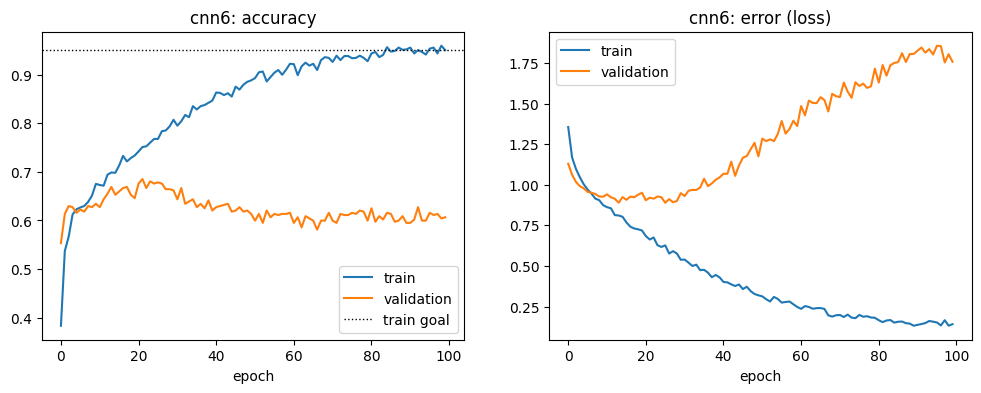

                  precision    recall  f1-score   support

    daytime_7day      0.507     0.424     0.462        85
 daytime_weekday      0.766     0.825     0.794       103
       flat_7day      0.786     0.824     0.804       187
weekday_moderate      0.444     0.424     0.434        66

        accuracy                          0.687       441
       macro avg      0.626     0.624     0.624       441
    weighted avg      0.676     0.687     0.680       441



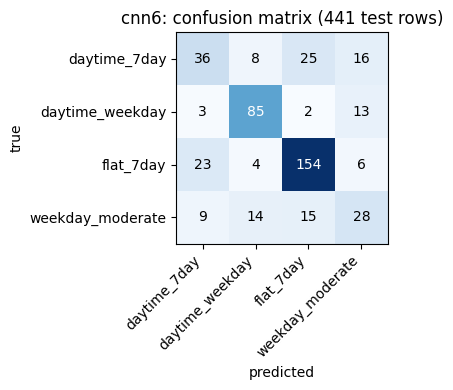

cnn6: train acc 0.951 | val acc 0.606 (best 0.685) | gap +0.344 | val loss 1.757 | epochs 100 | params 41,636 | val bal acc 0.544
vs parent cnn3: train acc 0.998 -> 0.951, val acc 0.581 -> 0.606, gap 0.417 -> 0.344, val bal acc 0.511 -> 0.544, val loss 2.686 -> 1.757 (regularization lowers training accuracy on purpose; judge by validation and the gap)


In [33]:
# ===================== CNN 6: SINGLE METHOD =====================
# CHANGE FROM THE PHASE-2 PARENT: Dropout 0.3 only
single("cnn6", "cnn", "dropout")

---
# cnn7: +early stopping
**Change from the phase-2 parent:** one method, early stopping (description printed with the model).

cnn7: from cnn3: early stopping on validation loss, patience 10 epochs, keep the best weights (week 5/6)


Model: "cnn7"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ monthly_sequence    │ (None, 12, 2)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_16 (Conv1D)  │ (None, 12, 32)    │        224 │ monthly_sequence… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_16    │ (None, 6, 32)     │          0 │ conv1d_16[0][0]   │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_17 (Conv1D)  │ (None, 6, 64)     │      6,208 │ max_pooling1d_16… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_17    │ (None, 3, 64)     │          0 │ conv1d_17[0][0]   │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_18 (Conv1D)  │ (None, 3, 128)    │     24,704 │ max_pooling1d_17… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_18    │ (None, 1, 128)    │          0 │ conv1d_18[0][0]   │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ max_pooling1d_18… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ other_features      │ (None, 31)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_7       │ (None, 159)       │          0 │ global_average_p… │
│ (Concatenate)       │                   │            │ other_features[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_59 (Dense)    │ (None, 64)        │     10,240 │ concatenate_7[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_60 (Dense)    │ (None, 4)         │        260 │ dense_59[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 41,636 (162.64 KB)

 Trainable params: 41,636 (162.64 KB)

 Non-trainable params: 0 (0.00 B)

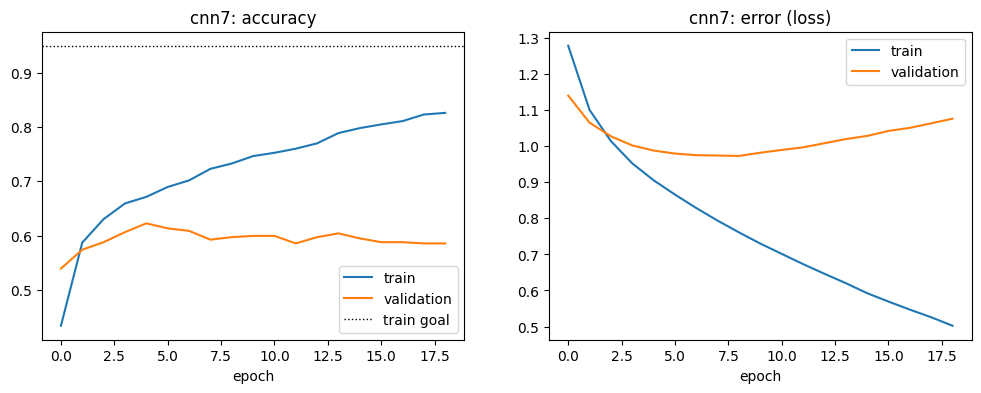

                  precision    recall  f1-score   support

    daytime_7day      0.455     0.659     0.538        85
 daytime_weekday      0.886     0.757     0.817       103
       flat_7day      0.877     0.684     0.769       187
weekday_moderate      0.452     0.576     0.507        66

        accuracy                          0.680       441
       macro avg      0.668     0.669     0.658       441
    weighted avg      0.734     0.680     0.696       441



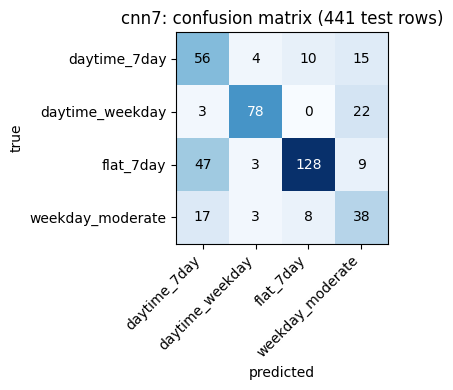

cnn7: train acc 0.826 | val acc 0.586 (best 0.623) | gap +0.241 | val loss 1.077 | epochs 19 | params 41,636 | val bal acc 0.585
vs parent cnn3: train acc 0.998 -> 0.826, val acc 0.581 -> 0.586, gap 0.417 -> 0.241, val bal acc 0.511 -> 0.585, val loss 2.686 -> 1.077 (regularization lowers training accuracy on purpose; judge by validation and the gap)


In [34]:
# ===================== CNN 7: SINGLE METHOD =====================
# CHANGE FROM THE PHASE-2 PARENT: early stopping only
single("cnn7", "cnn", "early_stop")

---
# cnn8: +BatchNorm
**Change from the phase-2 parent:** one method, BatchNorm (description printed with the model).

cnn8: from cnn3: BatchNormalization after each Dense / Conv1D layer (week 5/6)


Model: "cnn8"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ monthly_sequence    │ (None, 12, 2)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_19 (Conv1D)  │ (None, 12, 32)    │        224 │ monthly_sequence… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 12, 32)    │        128 │ conv1d_19[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_19    │ (None, 6, 32)     │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_20 (Conv1D)  │ (None, 6, 64)     │      6,208 │ max_pooling1d_19… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 6, 64)     │        256 │ conv1d_20[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_20    │ (None, 3, 64)     │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_21 (Conv1D)  │ (None, 3, 128)    │     24,704 │ max_pooling1d_20… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 3, 128)    │        512 │ conv1d_21[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_21    │ (None, 1, 128)    │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ max_pooling1d_21… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ other_features      │ (None, 31)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_8       │ (None, 159)       │          0 │ global_average_p… │
│ (Concatenate)       │                   │            │ other_features[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_61 (Dense)    │ (None, 64)        │     10,240 │ concatenate_8[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64)        │        256 │ dense_61[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_62 (Dense)    │ (None, 4)         │        260 │ batch_normalizat… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 42,788 (167.14 KB)

 Trainable params: 42,212 (164.89 KB)

 Non-trainable params: 576 (2.25 KB)

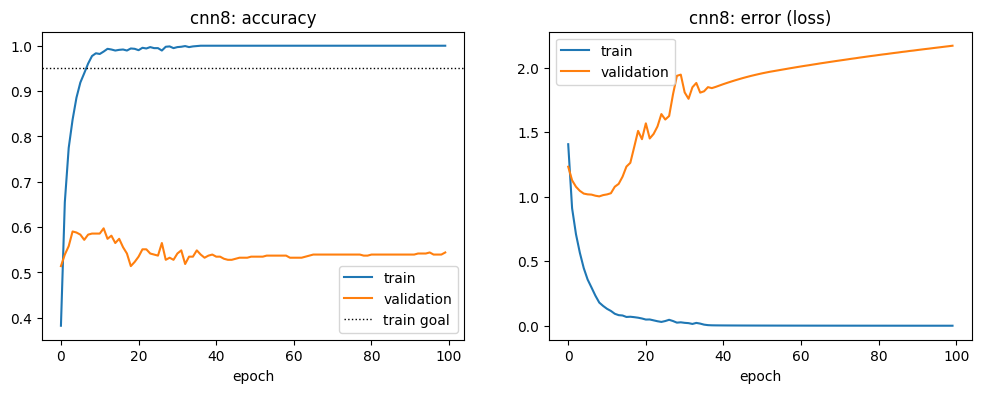

                  precision    recall  f1-score   support

    daytime_7day      0.407     0.259     0.317        85
 daytime_weekday      0.735     0.806     0.769       103
       flat_7day      0.728     0.802     0.763       187
weekday_moderate      0.441     0.455     0.448        66

        accuracy                          0.646       441
       macro avg      0.578     0.580     0.574       441
    weighted avg      0.625     0.646     0.631       441



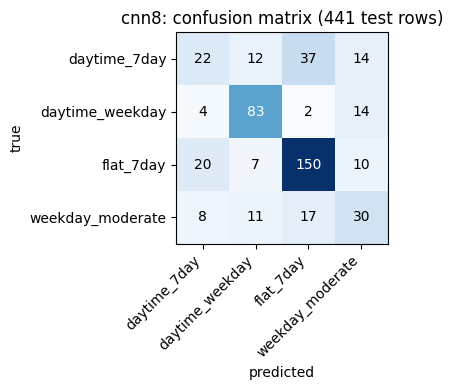

cnn8: train acc 1.000 | val acc 0.544 (best 0.597) | gap +0.456 | val loss 2.170 | epochs 100 | params 42,788 | val bal acc 0.479
vs parent cnn3: train acc 0.998 -> 1.000, val acc 0.581 -> 0.544, gap 0.417 -> 0.456, val bal acc 0.511 -> 0.479, val loss 2.686 -> 2.170 (regularization lowers training accuracy on purpose; judge by validation and the gap)


In [35]:
# ===================== CNN 8: SINGLE METHOD =====================
# CHANGE FROM THE PHASE-2 PARENT: BatchNorm only
single("cnn8", "cnn", "batchnorm")

---
# cnn9: +augmentation
**Change from the phase-2 parent:** one method, augmentation (description printed with the model).

cnn9: from cnn3: data augmentation (week 8/9): all 10 billing-offset copies of each training building for 1/10 of the epochs, so the number of weight updates equals the parent's


Model: "cnn9"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ monthly_sequence    │ (None, 12, 2)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_22 (Conv1D)  │ (None, 12, 32)    │        224 │ monthly_sequence… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_22    │ (None, 6, 32)     │          0 │ conv1d_22[0][0]   │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_23 (Conv1D)  │ (None, 6, 64)     │      6,208 │ max_pooling1d_22… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_23    │ (None, 3, 64)     │          0 │ conv1d_23[0][0]   │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_24 (Conv1D)  │ (None, 3, 128)    │     24,704 │ max_pooling1d_23… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_24    │ (None, 1, 128)    │          0 │ conv1d_24[0][0]   │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ max_pooling1d_24… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ other_features      │ (None, 31)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_9       │ (None, 159)       │          0 │ global_average_p… │
│ (Concatenate)       │                   │            │ other_features[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_63 (Dense)    │ (None, 64)        │     10,240 │ concatenate_9[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_64 (Dense)    │ (None, 4)         │        260 │ dense_63[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 41,636 (162.64 KB)

 Trainable params: 41,636 (162.64 KB)

 Non-trainable params: 0 (0.00 B)

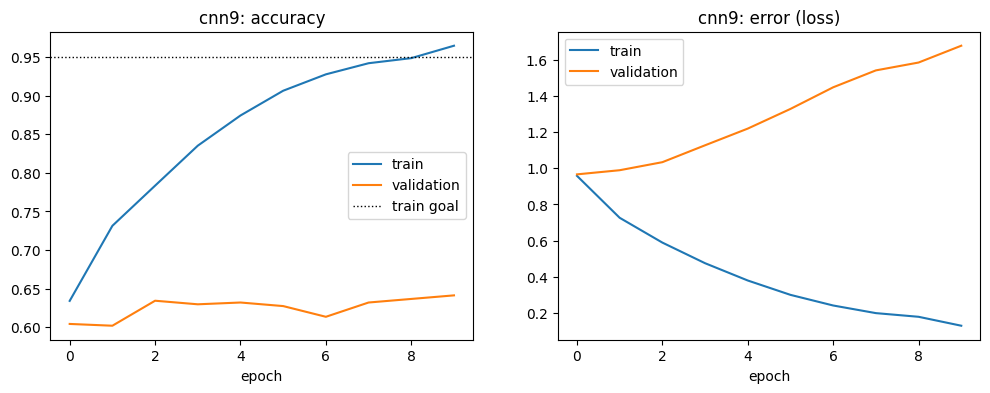

                  precision    recall  f1-score   support

    daytime_7day      0.493     0.388     0.434        85
 daytime_weekday      0.788     0.796     0.792       103
       flat_7day      0.812     0.765     0.788       187
weekday_moderate      0.383     0.545     0.450        66

        accuracy                          0.667       441
       macro avg      0.619     0.624     0.616       441
    weighted avg      0.681     0.667     0.670       441



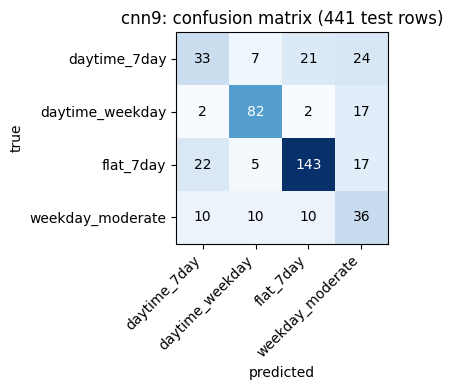

cnn9: train acc 0.965 | val acc 0.641 (best 0.641) | gap +0.324 | val loss 1.679 | epochs 10 | params 41,636 | val bal acc 0.608
vs parent cnn3: train acc 0.998 -> 0.965, val acc 0.581 -> 0.641, gap 0.417 -> 0.324, val bal acc 0.511 -> 0.608, val loss 2.686 -> 1.679 (regularization lowers training accuracy on purpose; judge by validation and the gap)


In [36]:
# ===================== CNN 9: SINGLE METHOD =====================
# CHANGE FROM THE PHASE-2 PARENT: augmentation only
single("cnn9", "cnn", "augmentation")

---
# cnn10: +step decay
**Change from the phase-2 parent:** one method, step decay (description printed with the model).

cnn10: from cnn3: step-decay learning rate (week 5/6): 1e-3 halved every 10 epochs


Model: "cnn10"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ monthly_sequence    │ (None, 12, 2)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_25 (Conv1D)  │ (None, 12, 32)    │        224 │ monthly_sequence… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_25    │ (None, 6, 32)     │          0 │ conv1d_25[0][0]   │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_26 (Conv1D)  │ (None, 6, 64)     │      6,208 │ max_pooling1d_25… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_26    │ (None, 3, 64)     │          0 │ conv1d_26[0][0]   │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_27 (Conv1D)  │ (None, 3, 128)    │     24,704 │ max_pooling1d_26… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_27    │ (None, 1, 128)    │          0 │ conv1d_27[0][0]   │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ max_pooling1d_27… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ other_features      │ (None, 31)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_10      │ (None, 159)       │          0 │ global_average_p… │
│ (Concatenate)       │                   │            │ other_features[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_65 (Dense)    │ (None, 64)        │     10,240 │ concatenate_10[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_66 (Dense)    │ (None, 4)         │        260 │ dense_65[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 41,636 (162.64 KB)

 Trainable params: 41,636 (162.64 KB)

 Non-trainable params: 0 (0.00 B)

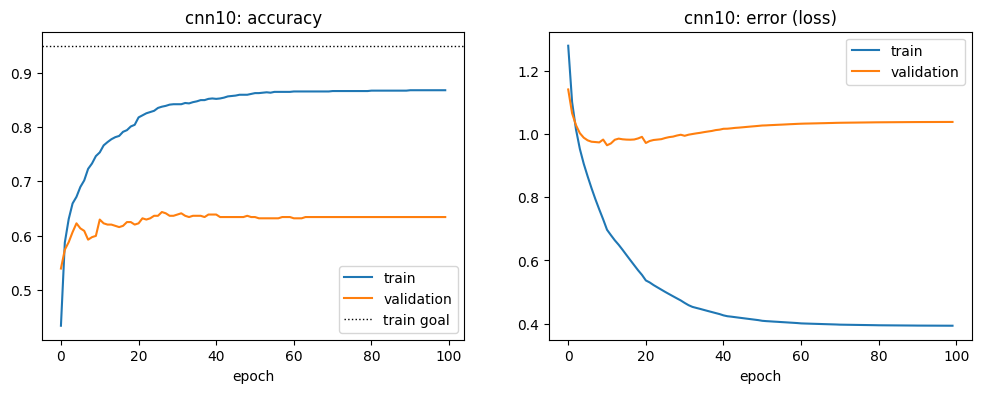

                  precision    recall  f1-score   support

    daytime_7day      0.462     0.424     0.442        85
 daytime_weekday      0.827     0.786     0.806       103
       flat_7day      0.818     0.791     0.804       187
weekday_moderate      0.405     0.515     0.453        66

        accuracy                          0.678       441
       macro avg      0.628     0.629     0.626       441
    weighted avg      0.689     0.678     0.682       441



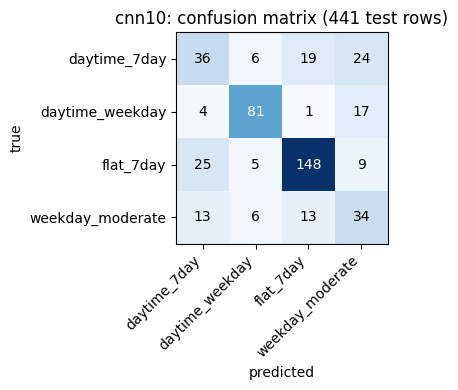

cnn10: train acc 0.868 | val acc 0.634 (best 0.644) | gap +0.234 | val loss 1.038 | epochs 100 | params 41,636 | val bal acc 0.586
vs parent cnn3: train acc 0.998 -> 0.868, val acc 0.581 -> 0.634, gap 0.417 -> 0.234, val bal acc 0.511 -> 0.586, val loss 2.686 -> 1.038 (regularization lowers training accuracy on purpose; judge by validation and the gap)


In [37]:
# ===================== CNN 10: SINGLE METHOD =====================
# CHANGE FROM THE PHASE-2 PARENT: step decay only
single("cnn10", "cnn", "step_decay")

---
## CNN phase 2, step B: combine what worked
Iterative, validation only: start from the best single method, add the next-best improving method, keep it only if validation balanced accuracy improves, otherwise drop it and try the next (at most 4 added steps). Each trained combination is shown with its curves and test report below; the log at the end lists every step.

single methods, validation balanced accuracy change vs parent cnn3 (0.511):
  augmentation  +0.097
  step decay    +0.075
  early stop    +0.074
  Dropout       +0.033
  L2 1e-5       +0.020
  L2 1e-3       +0.017  (weaker L2 strength, not used)
  BatchNorm     -0.032  (did not improve, not used)
start: cnn9 = parent + augmentation, val bal acc 0.608

===================== CNN_COMBO1: try adding step decay to cnn9 =====================
cnn_combo1: from cnn3: data augmentation (week 8/9): all 10 billing-offset copies of each training building for 1/10 of the epochs, so the number of weight updates equals the parent's; step-decay learning rate (week 5/6): 1e-3 halved every 10 epochs


Model: "cnn_combo1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ monthly_sequence    │ (None, 12, 2)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_28 (Conv1D)  │ (None, 12, 32)    │        224 │ monthly_sequence… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_28    │ (None, 6, 32)     │          0 │ conv1d_28[0][0]   │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_29 (Conv1D)  │ (None, 6, 64)     │      6,208 │ max_pooling1d_28… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_29    │ (None, 3, 64)     │          0 │ conv1d_29[0][0]   │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_30 (Conv1D)  │ (None, 3, 128)    │     24,704 │ max_pooling1d_29… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_30    │ (None, 1, 128)    │          0 │ conv1d_30[0][0]   │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ max_pooling1d_30… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ other_features      │ (None, 31)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_11      │ (None, 159)       │          0 │ global_average_p… │
│ (Concatenate)       │                   │            │ other_features[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_67 (Dense)    │ (None, 64)        │     10,240 │ concatenate_11[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_68 (Dense)    │ (None, 4)         │        260 │ dense_67[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 41,636 (162.64 KB)

 Trainable params: 41,636 (162.64 KB)

 Non-trainable params: 0 (0.00 B)

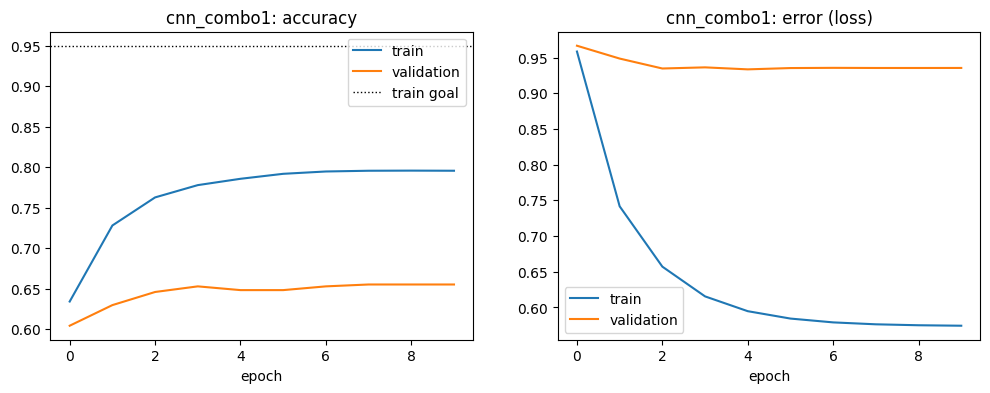

                  precision    recall  f1-score   support

    daytime_7day      0.489     0.506     0.497        85
 daytime_weekday      0.844     0.786     0.814       103
       flat_7day      0.867     0.770     0.816       187
weekday_moderate      0.385     0.530     0.446        66

        accuracy                          0.687       441
       macro avg      0.646     0.648     0.643       441
    weighted avg      0.717     0.687     0.699       441



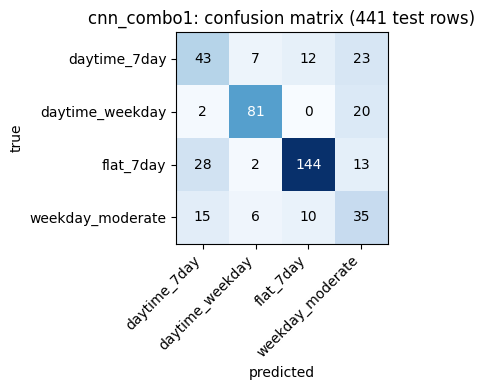

cnn_combo1: train acc 0.796 | val acc 0.655 (best 0.655) | gap +0.140 | val loss 0.935 | epochs 10 | params 41,636 | val bal acc 0.619
vs parent cnn3: train acc 0.998 -> 0.796, val acc 0.581 -> 0.655, gap 0.417 -> 0.140, val bal acc 0.511 -> 0.619, val loss 2.686 -> 0.935 (regularization lowers training accuracy on purpose; judge by validation and the gap)
step 1: add step decay: val bal acc 0.608 -> 0.619 -> KEPT

===================== CNN_COMBO2: try adding early stop to cnn_combo1 =====================
cnn_combo2: from cnn3: data augmentation (week 8/9): all 10 billing-offset copies of each training building for 1/10 of the epochs, so the number of weight updates equals the parent's; step-decay learning rate (week 5/6): 1e-3 halved every 10 epochs; early stopping on validation loss, patience 10 epochs, keep the best weights (week 5/6)


Model: "cnn_combo2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ monthly_sequence    │ (None, 12, 2)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_31 (Conv1D)  │ (None, 12, 32)    │        224 │ monthly_sequence… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_31    │ (None, 6, 32)     │          0 │ conv1d_31[0][0]   │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_32 (Conv1D)  │ (None, 6, 64)     │      6,208 │ max_pooling1d_31… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_32    │ (None, 3, 64)     │          0 │ conv1d_32[0][0]   │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_33 (Conv1D)  │ (None, 3, 128)    │     24,704 │ max_pooling1d_32… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_33    │ (None, 1, 128)    │          0 │ conv1d_33[0][0]   │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ max_pooling1d_33… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ other_features      │ (None, 31)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_12      │ (None, 159)       │          0 │ global_average_p… │
│ (Concatenate)       │                   │            │ other_features[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_69 (Dense)    │ (None, 64)        │     10,240 │ concatenate_12[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_70 (Dense)    │ (None, 4)         │        260 │ dense_69[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 41,636 (162.64 KB)

 Trainable params: 41,636 (162.64 KB)

 Non-trainable params: 0 (0.00 B)

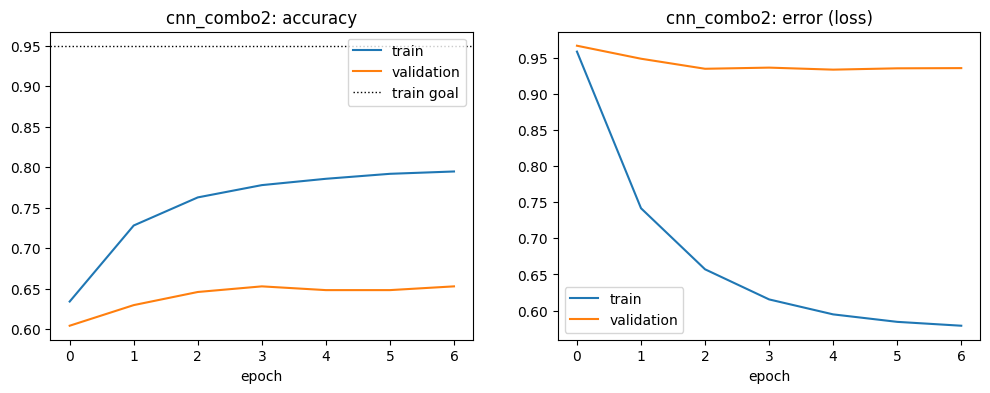

                  precision    recall  f1-score   support

    daytime_7day      0.494     0.482     0.488        85
 daytime_weekday      0.835     0.786     0.810       103
       flat_7day      0.869     0.781     0.823       187
weekday_moderate      0.376     0.530     0.440        66

        accuracy                          0.687       441
       macro avg      0.644     0.645     0.640       441
    weighted avg      0.715     0.687     0.698       441



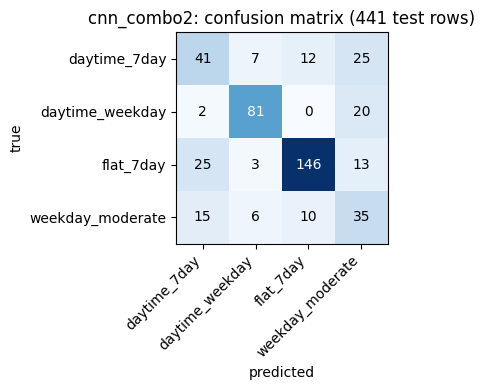

cnn_combo2: train acc 0.795 | val acc 0.653 (best 0.653) | gap +0.142 | val loss 0.936 | epochs 7 | params 41,636 | val bal acc 0.608
vs parent cnn3: train acc 0.998 -> 0.795, val acc 0.581 -> 0.653, gap 0.417 -> 0.142, val bal acc 0.511 -> 0.608, val loss 2.686 -> 0.936 (regularization lowers training accuracy on purpose; judge by validation and the gap)
step 2: add early stop: val bal acc 0.619 -> 0.608 -> dropped

===================== CNN_COMBO3: try adding Dropout to cnn_combo1 =====================
cnn_combo3: from cnn3: data augmentation (week 8/9): all 10 billing-offset copies of each training building for 1/10 of the epochs, so the number of weight updates equals the parent's; step-decay learning rate (week 5/6): 1e-3 halved every 10 epochs; Dropout 0.3 after each hidden layer, or after global average pooling and the Dense layer in a CNN (week 5/6: rate 0.2 to 0.5)


Model: "cnn_combo3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ monthly_sequence    │ (None, 12, 2)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_34 (Conv1D)  │ (None, 12, 32)    │        224 │ monthly_sequence… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_34    │ (None, 6, 32)     │          0 │ conv1d_34[0][0]   │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_35 (Conv1D)  │ (None, 6, 64)     │      6,208 │ max_pooling1d_34… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_35    │ (None, 3, 64)     │          0 │ conv1d_35[0][0]   │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_36 (Conv1D)  │ (None, 3, 128)    │     24,704 │ max_pooling1d_35… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_36    │ (None, 1, 128)    │          0 │ conv1d_36[0][0]   │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ max_pooling1d_36… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_10          │ (None, 128)       │          0 │ global_average_p… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ other_features      │ (None, 31)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_13      │ (None, 159)       │          0 │ dropout_10[0][0], │
│ (Concatenate)       │                   │            │ other_features[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_71 (Dense)    │ (None, 64)        │     10,240 │ concatenate_13[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_11          │ (None, 64)        │          0 │ dense_71[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_72 (Dense)    │ (None, 4)         │        260 │ dropout_11[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 41,636 (162.64 KB)

 Trainable params: 41,636 (162.64 KB)

 Non-trainable params: 0 (0.00 B)

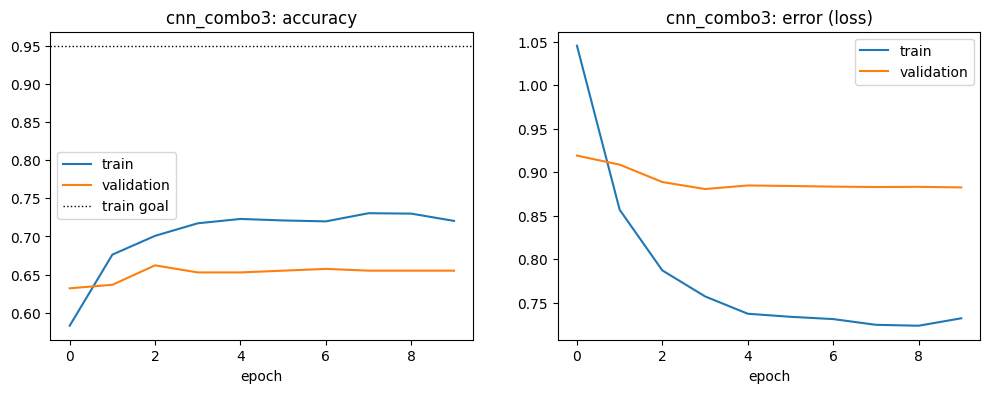

                  precision    recall  f1-score   support

    daytime_7day      0.569     0.482     0.522        85
 daytime_weekday      0.857     0.757     0.804       103
       flat_7day      0.860     0.818     0.838       187
weekday_moderate      0.410     0.621     0.494        66

        accuracy                          0.710       441
       macro avg      0.674     0.670     0.665       441
    weighted avg      0.736     0.710     0.718       441



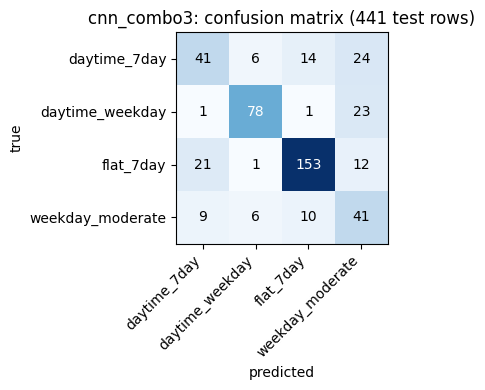

cnn_combo3: train acc 0.720 | val acc 0.655 (best 0.662) | gap +0.065 | val loss 0.883 | epochs 10 | params 41,636 | val bal acc 0.610
vs parent cnn3: train acc 0.998 -> 0.720, val acc 0.581 -> 0.655, gap 0.417 -> 0.065, val bal acc 0.511 -> 0.610, val loss 2.686 -> 0.883 (regularization lowers training accuracy on purpose; judge by validation and the gap)
step 3: add Dropout: val bal acc 0.619 -> 0.610 -> dropped

===================== CNN_COMBO4: try adding L2 1e-5 to cnn_combo1 =====================
cnn_combo4: from cnn3: data augmentation (week 8/9): all 10 billing-offset copies of each training building for 1/10 of the epochs, so the number of weight updates equals the parent's; step-decay learning rate (week 5/6): 1e-3 halved every 10 epochs; L2 regularization 1e-5 on every Dense / Conv1D layer (week 5/6: start with a small value)


Model: "cnn_combo4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ monthly_sequence    │ (None, 12, 2)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_37 (Conv1D)  │ (None, 12, 32)    │        224 │ monthly_sequence… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_37    │ (None, 6, 32)     │          0 │ conv1d_37[0][0]   │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_38 (Conv1D)  │ (None, 6, 64)     │      6,208 │ max_pooling1d_37… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_38    │ (None, 3, 64)     │          0 │ conv1d_38[0][0]   │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_39 (Conv1D)  │ (None, 3, 128)    │     24,704 │ max_pooling1d_38… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_39    │ (None, 1, 128)    │          0 │ conv1d_39[0][0]   │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ max_pooling1d_39… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ other_features      │ (None, 31)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_14      │ (None, 159)       │          0 │ global_average_p… │
│ (Concatenate)       │                   │            │ other_features[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_73 (Dense)    │ (None, 64)        │     10,240 │ concatenate_14[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_74 (Dense)    │ (None, 4)         │        260 │ dense_73[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 41,636 (162.64 KB)

 Trainable params: 41,636 (162.64 KB)

 Non-trainable params: 0 (0.00 B)

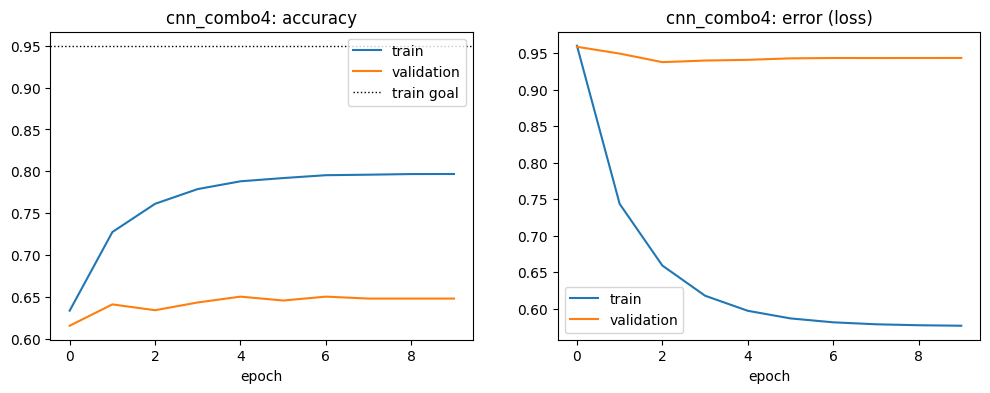

                  precision    recall  f1-score   support

    daytime_7day      0.488     0.494     0.491        85
 daytime_weekday      0.842     0.777     0.808       103
       flat_7day      0.852     0.770     0.809       187
weekday_moderate      0.374     0.515     0.433        66

        accuracy                          0.680       441
       macro avg      0.639     0.639     0.635       441
    weighted avg      0.708     0.680     0.691       441



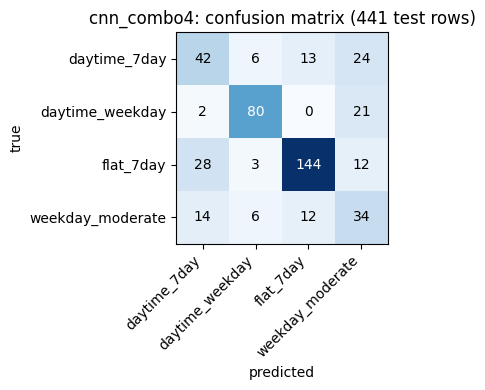

cnn_combo4: train acc 0.797 | val acc 0.648 (best 0.650) | gap +0.149 | val loss 0.944 | epochs 10 | params 41,636 | val bal acc 0.612
vs parent cnn3: train acc 0.998 -> 0.797, val acc 0.581 -> 0.648, gap 0.417 -> 0.149, val bal acc 0.511 -> 0.612, val loss 2.686 -> 0.944 (regularization lowers training accuracy on purpose; judge by validation and the gap)
step 4: add L2 1e-5: val bal acc 0.619 -> 0.612 -> dropped

best cnn model after the loop: cnn_combo1 (augmentation + step decay)


,step,model,added,methods,val_bal_acc_before,val_bal_acc_after,kept
0,1,cnn_combo1,step decay,augmentation + step decay,0.608,0.619,True
1,2,cnn_combo2,early stop,augmentation + step decay + early stop,0.619,0.608,False
2,3,cnn_combo3,Dropout,augmentation + step decay + Dropout,0.619,0.610,False
3,4,cnn_combo4,L2 1e-5,augmentation + step decay + L2 1e-5,0.619,0.612,False


In [38]:
FINAL_CNN, cnn_combo_log = combine("cnn")
with pd.option_context("display.max_colwidth", None, "display.max_columns", None, "display.width", 250):
    display(cnn_combo_log)

In [39]:
# CNN phase 2 rows of the running table, with the change against the parent
print("final CNN (best after the combination loop):", FINAL_CNN)
block_table([n for n in runs if n.startswith("cnn") and runs[n]["phase"] == 2])

final CNN (best after the combination loop): cnn_combo1


,label,train_acc,val_acc,gap,epochs,val_bal_acc,parent,val_bal_acc_vs_parent,gap_vs_parent
cnn4,+L2 1e-5,0.998,0.597,0.401,100.0,0.531,cnn3,0.020,-0.015
cnn5,+L2 1e-3,0.993,0.576,0.417,100.0,0.528,cnn3,0.017,0.000
cnn6,+Dropout 0.3,0.951,0.606,0.344,100.0,0.544,cnn3,0.033,-0.073
cnn7,+early stopping,0.826,0.586,0.241,19.0,0.585,cnn3,0.074,-0.176
cnn8,+BatchNorm,1.000,0.544,0.456,100.0,0.479,cnn3,-0.032,0.039
cnn9,+augmentation,0.965,0.641,0.324,10.0,0.608,cnn3,0.097,-0.093
cnn10,+step decay,0.868,0.634,0.234,100.0,0.586,cnn3,0.075,-0.183
cnn_combo1,combo: augmentation + step decay,0.796,0.655,0.140,10.0,0.619,cnn3,0.107,-0.276
cnn_combo2,combo: augmentation + step decay + early stop,0.795,0.653,0.142,7.0,0.608,cnn3,0.097,-0.275
cnn_combo3,combo: augmentation + step decay + Dropout,0.720,0.655,0.065,10.0,0.610,cnn3,0.099,-0.351


---
# 3. Hyperparameter tuning of the two final models with K-fold cross-validation (week 8/9)
The validation set has only 264 buildings, so small differences are within noise. K-fold cross-validation (week 8/9) reuses the training data: split it into K = 4 folds, train each set of hyperparameters (week 3 list) on 3 folds and score it on the 4th, 4 times, and average. The **test buildings are never used here**; they stay as the untouched hold-out.

- Folds are made of whole buildings (`StratifiedGroupKFold` on `building_key`; grouping is not covered in the lectures).
- Inside each fold, 1/6 of the training-fold buildings are set aside for early stopping (used only by models that early-stop) so the scored fold never decides when training stops.
- Standardization and class weights are recomputed on each fold's training rows (week 8/9: training statistics only).
- Everything phase 2 settled (regularization method, epochs, augmentation) stays as in the final model. Tuned here (week 3 list): dense = learning rate; CNN = pooling type, max vs average (week 4). Batch size (64) and kernel size (3) stay fixed to keep the notebook within about 15 minutes on Colab; add values to `DENSE_BATCHES` or `CNN_KERNELS` to try more sets.

In [40]:
# Hyperparameter sets to try (week 3 list)
DENSE_LRS = [1e-2, 1e-3]
DENSE_BATCHES = [64]
CNN_KERNELS = [3]
CNN_POOLS = ["max", "average"]


In [41]:
# ---- Step 1 (week 8/9): split the training data (train + validation buildings, not test) into K = 4 folds ----
K = 4
cv_rows = base & ~is_test
skf4 = StratifiedGroupKFold(n_splits=K, shuffle=True, random_state=SPLIT_SEED)
cv_folds = []
for k, (tr_i, ho_i) in enumerate(skf4.split(features[cv_rows], y_all[cv_rows], groups[cv_rows])):
    tr_b, ho_b = np.unique(groups[cv_rows][tr_i]), np.unique(groups[cv_rows][ho_i])
    stop_b = np.random.default_rng(k).choice(tr_b, size=len(tr_b) // 6, replace=False)   # early-stopping buildings
    fit = np.isin(groups, np.setdiff1d(tr_b, stop_b))           # all copies of the training-fold buildings
    stop = np.isin(groups, stop_b) & base
    hold = np.isin(groups, ho_b) & base                         # the hold-out fold, un-augmented rows
    assert not set(ho_b) & set(test_b) and not set(tr_b) & set(test_b) and not set(ho_b) & set(tr_b)
    m, s = features[fit].mean(), features[fit].std().replace(0, 1)          # this fold's training statistics
    cv_folds.append(dict(fit=fit, stop=stop, hold=hold, X=((features - m) / s).values.astype("float32"),
                         cw=make_class_weight(y_all[fit & base])))
    print(f"fold {k}: {len(tr_b) - len(stop_b)} training buildings ({(fit & base).sum()} un-augmented rows), "
          f"{len(stop_b)} early-stopping buildings, {len(ho_b)} hold-out buildings ({hold.sum()} rows)")

def run_cv(fit_predict):
    """Steps 3 to 6 (week 8/9) for ONE set of hyperparameters: train on 3 folds, score the 4th, repeat K times."""
    rows = []
    for k, f in enumerate(cv_folds):
        keras.utils.set_random_seed(SEED + k)
        p = fit_predict(f)                                       # step 3: train on the training folds
        s = scores(y_all[f["hold"]], p.argmax(1))                # step 4: evaluate on the hold-out fold
        rows.append({"fold": k, "bal_acc": s["bal_acc"], "shave_recall": s["shave_recall"], "shave_precision": s["shave_precision"]})
    return pd.DataFrame(rows)                                    # step 5 done: one row per fold

def spec_fp(spec, **hp):
    def fp(f):
        m = fit_from_spec(spec, f["X"], f["fit"], f["stop"], f["cw"], **hp)
        return m.predict(inputs_for(spec, f["X"][f["hold"]]), verbose=0)
    return fp

def summarize(runs_by_set):
    """Step 6 (week 8/9): aggregate across the 4 folds, mean and std per hyperparameter set."""
    t = pd.DataFrame({name: {"bal_acc_mean": r.bal_acc.mean(), "bal_acc_std": r.bal_acc.std(),
                             "shave_recall_mean": r.shave_recall.mean(), "shave_precision_mean": r.shave_precision.mean()}
                      for name, r in runs_by_set.items()}).T
    return t.sort_values("bal_acc_mean", ascending=False).round(3)
cv_runs = {}   # per-fold results of the chosen sets, kept for section 4

fold 0: 661 training buildings (1078 un-augmented rows), 132 early-stopping buildings, 265 hold-out buildings (450 rows)
fold 1: 662 training buildings (1089 un-augmented rows), 132 early-stopping buildings, 264 hold-out buildings (433 rows)
fold 2: 661 training buildings (1105 un-augmented rows), 132 early-stopping buildings, 265 hold-out buildings (427 rows)
fold 3: 662 training buildings (1099 un-augmented rows), 132 early-stopping buildings, 264 hold-out buildings (440 rows)


## 3a. Final dense model: learning rate

In [42]:
# Steps 2 and 7 (week 8/9): choose a set of hyperparameters, run steps 3-6, repeat for every set
dense_sets = {}
for lr in DENSE_LRS:
    for batch in DENSE_BATCHES:
        name = f"lr={lr:g}, batch={batch}"
        dense_sets[name] = run_cv(spec_fp(SPECS[FINAL_DENSE], lr=lr, batch=batch))
        print(f"{name:<22} fold balanced accuracy: {dense_sets[name].bal_acc.round(3).tolist()}")
dense_table = summarize(dense_sets)
best = dense_table.index[0]
DENSE_BEST = dict(lr=float(best.split(",")[0].split("=")[1]), batch=int(best.split("=")[-1]))
cv_runs["dense_tuned"] = dense_sets[best]
print(f"\n{FINAL_DENSE} tuning, mean and std over {K} folds. Best set: {best}")
dense_table

lr=0.01, batch=64      fold balanced accuracy: [0.564, 0.571, 0.612, 0.598]
lr=0.001, batch=64     fold balanced accuracy: [0.577, 0.593, 0.629, 0.605]

dense6 tuning, mean and std over 4 folds. Best set: lr=0.001, batch=64


,bal_acc_mean,bal_acc_std,shave_recall_mean,shave_precision_mean
"lr=0.001, batch=64",0.601,0.022,0.819,0.785
"lr=0.01, batch=64",0.586,0.022,0.805,0.779


dense_tuned: dense6 with lr=0.001, batch=64 (chosen by 4-fold CV)


Model: "dense_tuned"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_22 (InputLayer)     │ (None, 55)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_99 (Dense)                │ (None, 64)             │         3,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_28 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_100 (Dense)               │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_29 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_101 (Dense)               │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,004 (31.27 KB)

 Trainable params: 8,004 (31.27 KB)

 Non-trainable params: 0 (0.00 B)

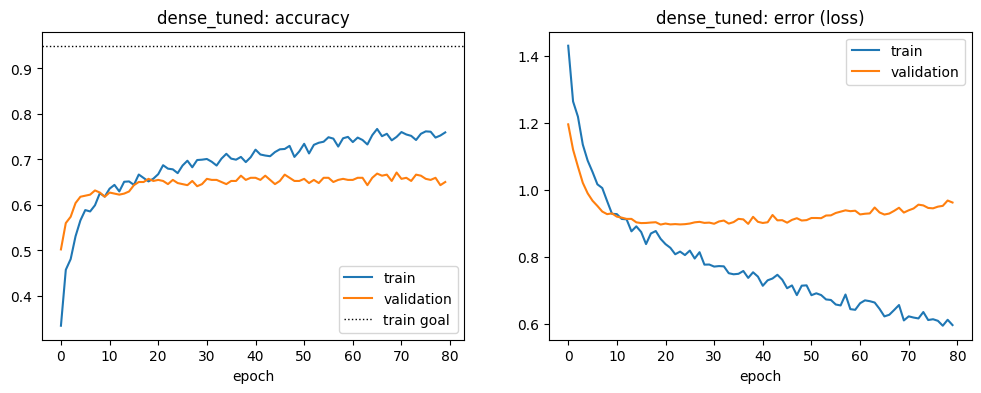

                  precision    recall  f1-score   support

    daytime_7day      0.468     0.518     0.492        85
 daytime_weekday      0.848     0.816     0.832       103
       flat_7day      0.877     0.727     0.795       187
weekday_moderate      0.419     0.591     0.491        66

        accuracy                          0.687       441
       macro avg      0.653     0.663     0.652       441
    weighted avg      0.723     0.687     0.700       441



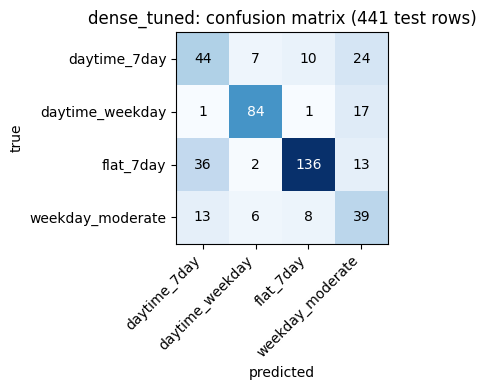

dense_tuned: train acc 0.759 | val acc 0.650 (best 0.671) | gap +0.109 | val loss 0.963 | epochs 80 | params 8,004 | val bal acc 0.620
vs dense6 before tuning: train acc 0.759 -> 0.759, val acc 0.650 -> 0.650, gap 0.109 -> 0.109, val bal acc 0.620 -> 0.620


In [43]:
# Retrain the best set on the normal training split, then score the test set once
train_spec("dense_tuned", "tuned", SPECS[FINAL_DENSE], FINAL_DENSE, f"{FINAL_DENSE} with {best} (chosen by 4-fold CV)",
           f"tuned: {best}", lr=DENSE_BEST["lr"], batch=DENSE_BEST["batch"]);

## 3b. Final CNN: pooling type

In [44]:
cnn_sets = {}
for ks in CNN_KERNELS:
    for pool in CNN_POOLS:
        name = f"kernel={ks}, pool={pool}"
        cnn_sets[name] = run_cv(spec_fp(SPECS[FINAL_CNN], kernel_size=ks, pooling=pool))
        print(f"{name:<24} fold balanced accuracy: {cnn_sets[name].bal_acc.round(3).tolist()}")
cnn_table = summarize(cnn_sets)
best = cnn_table.index[0]
CNN_BEST = dict(kernel_size=int(best.split(",")[0].split("=")[1]), pooling=best.split("=")[-1])
cv_runs["cnn_tuned"] = cnn_sets[best]
print(f"\n{FINAL_CNN} tuning, mean and std over {K} folds. Best set: {best}")
cnn_table

kernel=3, pool=max       fold balanced accuracy: [0.578, 0.565, 0.627, 0.604]
kernel=3, pool=average   fold balanced accuracy: [0.586, 0.578, 0.652, 0.611]

cnn_combo1 tuning, mean and std over 4 folds. Best set: kernel=3, pool=average


,bal_acc_mean,bal_acc_std,shave_recall_mean,shave_precision_mean
"kernel=3, pool=average",0.607,0.033,0.843,0.764
"kernel=3, pool=max",0.593,0.027,0.822,0.759


cnn_tuned: cnn_combo1 with kernel=3, pool=average (chosen by 4-fold CV)


Model: "cnn_tuned"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ monthly_sequence    │ (None, 12, 2)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_64 (Conv1D)  │ (None, 12, 32)    │        224 │ monthly_sequence… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ average_pooling1d_… │ (None, 6, 32)     │          0 │ conv1d_64[0][0]   │
│ (AveragePooling1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_65 (Conv1D)  │ (None, 6, 64)     │      6,208 │ average_pooling1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ average_pooling1d_… │ (None, 3, 64)     │          0 │ conv1d_65[0][0]   │
│ (AveragePooling1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_66 (Conv1D)  │ (None, 3, 128)    │     24,704 │ average_pooling1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ average_pooling1d_… │ (None, 1, 128)    │          0 │ conv1d_66[0][0]   │
│ (AveragePooling1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ average_pooling1… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ other_features      │ (None, 31)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_23      │ (None, 159)       │          0 │ global_average_p… │
│ (Concatenate)       │                   │            │ other_features[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_118 (Dense)   │ (None, 64)        │     10,240 │ concatenate_23[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_119 (Dense)   │ (None, 4)         │        260 │ dense_118[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 41,636 (162.64 KB)

 Trainable params: 41,636 (162.64 KB)

 Non-trainable params: 0 (0.00 B)

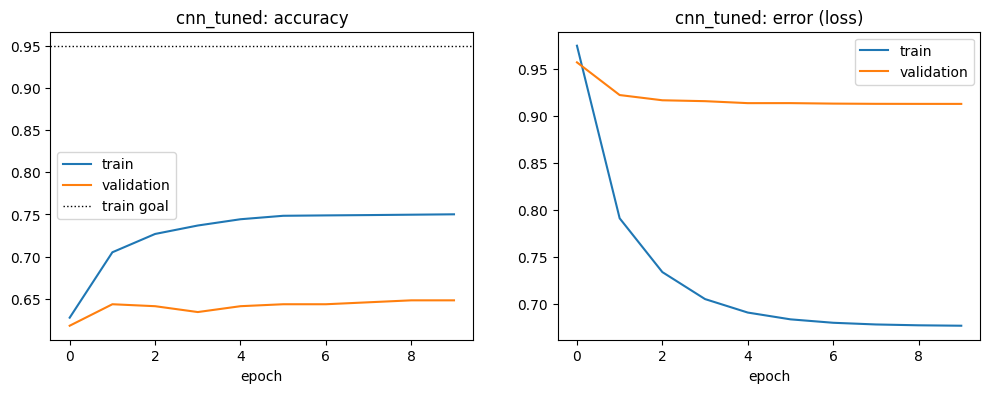

                  precision    recall  f1-score   support

    daytime_7day      0.461     0.482     0.471        85
 daytime_weekday      0.868     0.767     0.814       103
       flat_7day      0.868     0.775     0.819       187
weekday_moderate      0.372     0.530     0.438        66

        accuracy                          0.680       441
       macro avg      0.642     0.639     0.636       441
    weighted avg      0.715     0.680     0.694       441



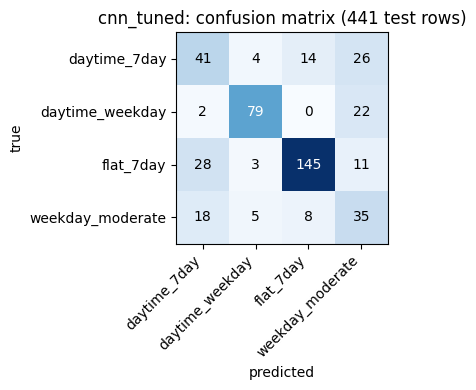

cnn_tuned: train acc 0.750 | val acc 0.648 (best 0.648) | gap +0.102 | val loss 0.913 | epochs 10 | params 41,636 | val bal acc 0.616
vs cnn_combo1 before tuning: train acc 0.796 -> 0.750, val acc 0.655 -> 0.648, gap 0.140 -> 0.102, val bal acc 0.619 -> 0.616


In [45]:
# Retrain the best set on the normal training split, then score the test set once
train_spec("cnn_tuned", "tuned", SPECS[FINAL_CNN], FINAL_CNN, f"{FINAL_CNN} with {best} (chosen by 4-fold CV)",
           f"tuned: {best}", **CNN_BEST);

---
# 4. Cross-validated comparison: final dense vs final CNN (same 4 folds)
The same 4 folds and hold-out buildings for each: the tuned final dense net and the tuned final CNN (their rows reuse the per-fold results of the best set from section 3). Mean and std over the folds; a gap smaller than about one std is within noise.

In [46]:
family = pd.DataFrame({name: {"bal_acc": f"{r.bal_acc.mean():.3f} +/- {r.bal_acc.std():.3f}",
                              "shave_recall_argmax": f"{r.shave_recall.mean():.3f} +/- {r.shave_recall.std():.3f}",
                              "shave_precision_argmax": f"{r.shave_precision.mean():.3f} +/- {r.shave_precision.std():.3f}",
                              "bal_acc_mean": r.bal_acc.mean()}
                       for name, r in cv_runs.items()}).T.sort_values("bal_acc_mean", ascending=False)
try:
    family.to_csv("results_01_family_cv.csv")
except Exception as e:
    print("could not save results_01_family_cv.csv:", e)
print(f"chance level for {len(classes)} classes: balanced accuracy {1 / len(classes):.2f}")
family

chance level for 4 classes: balanced accuracy 0.25


,bal_acc,shave_recall_argmax,shave_precision_argmax,bal_acc_mean
cnn_tuned,0.607 +/- 0.033,0.843 +/- 0.018,0.764 +/- 0.029,0.607048
dense_tuned,0.601 +/- 0.022,0.819 +/- 0.018,0.785 +/- 0.024,0.600986


---
# 5. Learning curves for the two final models (model diagnostic)
Week 2 shows how model skill depends on the number of training examples. Here the idea is used to compare the two final models: train each (phase-2 settings) on 50, 100, 200, 400 and all training buildings, with `REPS` repeats using different building draws (1 repeat here to fit the time budget, so the plot shows no spread; that is not certainty), and score test balanced accuracy. A curve still rising at the right would gain from more data; a flat curve means the model, the features or the label set the limit.

rep 0    50 buildings  dense6 0.476  cnn_combo1 0.394
rep 0   100 buildings  dense6 0.552  cnn_combo1 0.487
rep 0   200 buildings  dense6 0.648  cnn_combo1 0.571
rep 0   400 buildings  dense6 0.632  cnn_combo1 0.623
rep 0   794 buildings  dense6 0.643  cnn_combo1 0.621


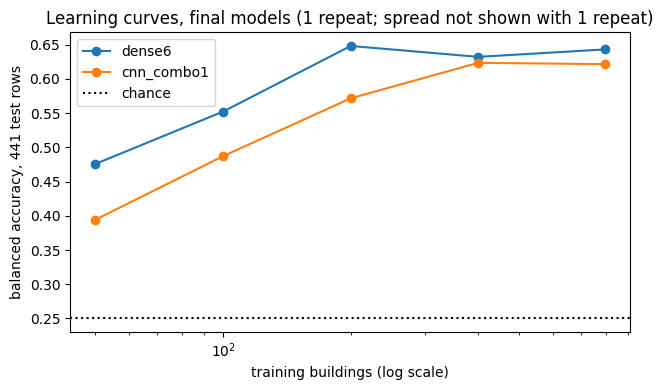

,dense6_mean,cnn_combo1_mean,dense6_std,cnn_combo1_std
training_buildings,,,,
50,0.476,0.394,0.0,0.0
100,0.552,0.487,0.0,0.0
200,0.648,0.571,0.0,0.0
400,0.632,0.623,0.0,0.0
794,0.643,0.621,0.0,0.0


In [47]:
SIZES = [50, 100, 200, 400, len(train_b)]
REPS = 1
lc = {name: {n: [] for n in SIZES} for name in [FINAL_DENSE, FINAL_CNN]}
for r in range(REPS):
    order = np.random.default_rng(r).permutation(train_b)
    for n in SIZES:
        sel = np.isin(groups, order[:n])                          # all copies of the first n training buildings
        for name in lc:
            keras.utils.set_random_seed(r)
            m = fit_from_spec(SPECS[name], Xz, sel, is_val, class_weight)
            lc[name][n].append(balanced_accuracy_score(y_test, m.predict(inputs_for(SPECS[name], x_test), verbose=0).argmax(1)))
        print(f"rep {r}  {n:>4} buildings  " + "  ".join(f"{k} {lc[k][n][-1]:.3f}" for k in lc))

fig, ax = plt.subplots(figsize=(6.5, 4))
for name in lc:
    mean = np.array([np.mean(lc[name][n]) for n in SIZES]); std = np.array([np.std(lc[name][n]) for n in SIZES])
    ax.plot(SIZES, mean, marker="o", label=name); ax.fill_between(SIZES, mean - std, mean + std, alpha=0.2)
ax.axhline(1 / len(classes), ls=":", color="k", label="chance"); ax.set_xscale("log")
ax.set_xlabel("training buildings (log scale)"); ax.set_ylabel(f"balanced accuracy, {len(y_test)} test rows")
ax.set_title(f"Learning curves, final models ({REPS} repeat{'s' if REPS > 1 else ''}; spread not shown with 1 repeat)" if REPS == 1 else f"Learning curves, final models ({REPS} repeats)"); ax.legend(); plt.tight_layout(); show("learning_curves_models")
lc_table = pd.DataFrame({f"{k}_mean": [np.mean(lc[k][n]) for n in SIZES] for k in lc}, index=pd.Index(SIZES, name="training_buildings"))
for k in lc: lc_table[f"{k}_std"] = [np.std(lc[k][n]) for n in SIZES]
lc_table.round(3)

---
# 6. Operating point for the target
Each model gives a probability per class. p_shaveable = P(daytime_weekday) + P(weekday_moderate). Calling a building "shaveable" when p_shaveable >= a threshold is the classification threshold of week 4: a lower threshold catches more shaveable buildings (higher recall, true positive rate) but flags more non-shaveable ones (higher false positive rate, lower precision).

The threshold is chosen on the **validation** set: the highest threshold that still gives recall >= TARGET_RECALL there. It is then applied unchanged to the test set.

The ROC curve plots true positive rate against false positive rate for every possible threshold, and AUC is the area under it (1.0 = perfect ranking, 0.5 = chance). True and false positive rates are week 4 metrics; the ROC curve and AUC themselves are not covered in the lectures.

In [48]:
def pick_threshold(p, is_pos, target=TARGET_RECALL):
    """Highest threshold t with recall(p >= t) >= target."""
    for t in np.sort(np.unique(p))[::-1]:          # try thresholds from high to low
        if (p[is_pos] >= t).mean() >= target:
            return t
    return 0.0

def shave_scores(p, is_pos, t):
    flag = p >= t
    return recall_score(is_pos, flag, zero_division=0), precision_score(is_pos, flag, zero_division=0)

val_pos, test_pos = np.isin(y_val, shave_idx), np.isin(y_test, shave_idx)
tuned = []
for name in test_proba:
    pv = val_proba[name][:, shave_idx].sum(1); pt = test_proba[name][:, shave_idx].sum(1)
    t = pick_threshold(pv, val_pos)
    r_all, p_all = shave_scores(pt, test_pos, t)
    r_conf, p_conf = shave_scores(pt[conf_test], test_pos[conf_test], t)
    tuned.append({"model": name, "threshold": t, "val_shave_recall": shave_scores(pv, val_pos, t)[0],
                  "all_shave_auc": roc_auc_score(test_pos, pt), "conf_shave_auc": roc_auc_score(test_pos[conf_test], pt[conf_test]),
                  "all_shave_recall_tuned": r_all, "all_shave_precision_tuned": p_all,
                  "conf_shave_recall_tuned": r_conf, "conf_shave_precision_tuned": p_conf})
tuned = pd.DataFrame(tuned).set_index("model")
tuned.loc[list(dict.fromkeys([DENSE_PARENT, FINAL_DENSE, "dense_tuned", CNN_PARENT, FINAL_CNN, "cnn_tuned"]))].round(3)

,threshold,val_shave_recall,all_shave_auc,conf_shave_auc,all_shave_recall_tuned,all_shave_precision_tuned,conf_shave_recall_tuned,conf_shave_precision_tuned
model,,,,,,,,
dense1,0.020,0.902,0.912,0.993,0.923,0.675,0.965,0.891
dense6,0.250,0.902,0.917,0.996,0.923,0.700,0.988,0.913
dense_tuned,0.250,0.902,0.917,0.996,0.923,0.700,0.988,0.913
cnn3,0.008,0.902,0.914,0.982,0.917,0.638,0.965,0.837
cnn_combo1,0.335,0.902,0.921,0.994,0.893,0.699,0.976,0.883
cnn_tuned,0.306,0.902,0.922,0.993,0.923,0.693,0.976,0.874


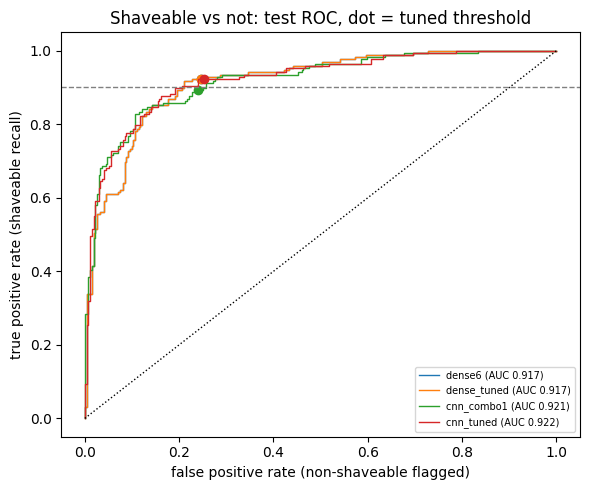

In [49]:
# ROC of the shaveable score on the test set, one line per final model, AUC in the legend, dot = tuned threshold
PLOT_MODELS = list(dict.fromkeys([FINAL_DENSE, "dense_tuned", FINAL_CNN, "cnn_tuned"]))
fig, ax = plt.subplots(figsize=(6, 5))
for name in PLOT_MODELS:
    pt = test_proba[name][:, shave_idx].sum(1)
    fpr, tpr, _ = roc_curve(test_pos, pt)
    line, = ax.plot(fpr, tpr, lw=1, label=f"{name} (AUC {tuned.loc[name, 'all_shave_auc']:.3f})")
    flag = pt >= tuned.loc[name, "threshold"]
    ax.plot(flag[~test_pos].mean(), flag[test_pos].mean(), "o", color=line.get_color())
ax.plot([0, 1], [0, 1], ls=":", color="k", lw=1); ax.axhline(TARGET_RECALL, ls="--", color="grey", lw=1)
ax.set_xlabel("false positive rate (non-shaveable flagged)"); ax.set_ylabel("true positive rate (shaveable recall)")
ax.set_title("Shaveable vs not: test ROC, dot = tuned threshold"); ax.legend(fontsize=7, loc="lower right"); plt.tight_layout(); show("shaveable_roc")

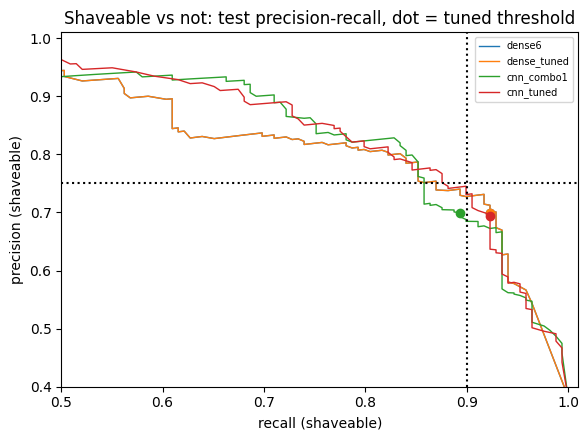

In [50]:
# Same decision seen as precision vs recall (the target is stated in these two week 4 metrics)
fig, ax = plt.subplots(figsize=(6, 4.5))
for name in PLOT_MODELS:
    pt = test_proba[name][:, shave_idx].sum(1)
    rp = np.array([shave_scores(pt, test_pos, t) for t in np.linspace(0, 1, 201)])
    line, = ax.plot(rp[:, 0], rp[:, 1], label=name, lw=1)
    ax.plot(*shave_scores(pt, test_pos, tuned.loc[name, "threshold"]), "o", color=line.get_color())
ax.axvline(TARGET_RECALL, ls=":", color="k"); ax.axhline(TARGET_PRECISION, ls=":", color="k")
ax.set_xlabel("recall (shaveable)"); ax.set_ylabel("precision (shaveable)"); ax.set_xlim(0.5, 1.01); ax.set_ylim(0.4, 1.01)
ax.set_title("Shaveable vs not: test precision-recall, dot = tuned threshold"); ax.legend(fontsize=7); plt.tight_layout(); show("shaveable_pr")

---
# 7. Summary of all models (single test split)
One row per model, in the order built: phase, train / validation accuracy and gap from the running table, then test scores on all rows and on confident rows. "argmax" = predicted class is the most probable one; "tuned" = shaveable if p_shaveable >= the validation-chosen threshold. `meets_target` = tuned shaveable recall >= TARGET_RECALL and precision >= TARGET_PRECISION on all test rows; `meets_target_conf` = same on confident rows. For ranking the final models, use the cross-validated table in section 4.

In [51]:
res = pd.DataFrame(results).set_index("model").join(tuned)
run_tab = pd.DataFrame(runs).T
summary = pd.DataFrame(index=res.index)
summary["phase"] = run_tab["phase"].reindex(res.index)
for c in ["train_acc", "val_acc", "best_val_acc", "gap", "epochs", "params", "val_bal_acc"]:
    summary[c] = pd.to_numeric(run_tab[c].reindex(res.index))
for s in ["all", "conf"]:
    summary[f"{s}_bal_acc"] = res[f"{s}_bal_acc"]
    for c in SHAVEABLE:
        summary[f"{s}_recall_{c}"] = res[f"{s}_recall_{c}"]
        summary[f"{s}_precision_{c}"] = res[f"{s}_precision_{c}"]
    summary[f"{s}_shave_auc"] = res[f"{s}_shave_auc"]
    summary[f"{s}_shave_recall_argmax"] = res[f"{s}_shave_recall"]
    summary[f"{s}_shave_precision_argmax"] = res[f"{s}_shave_precision"]
    summary[f"{s}_shave_recall_tuned"] = res[f"{s}_shave_recall_tuned"]
    summary[f"{s}_shave_precision_tuned"] = res[f"{s}_shave_precision_tuned"]
summary["threshold"] = res["threshold"]
summary["meets_target"] = (res.all_shave_recall_tuned >= TARGET_RECALL) & (res.all_shave_precision_tuned >= TARGET_PRECISION)
summary["meets_target_conf"] = (res.conf_shave_recall_tuned >= TARGET_RECALL) & (res.conf_shave_precision_tuned >= TARGET_PRECISION)
summary["cv4_bal_acc_mean"] = pd.Series({n: r.bal_acc.mean() for n, r in cv_runs.items()})
summary = summary.round(3)
try:
    summary.to_csv("results_01_models.csv"); print("saved results_01_models.csv")
except Exception as e:
    print("could not save results_01_models.csv:", e)
try:
    import google.colab
    from google.colab import files
    files.download("results_01_models.csv")      # Colab only: download the summary table
except ImportError:
    pass
except Exception as e:
    print("could not download results_01_models.csv:", e)
print(f"total runtime {(time.time() - T_START) / 60:.1f} min")
with pd.option_context("display.max_columns", None, "display.max_rows", None, "display.width", 250):
    display(summary.T)                           # every model is a column; nothing hidden behind "..."

saved results_01_models.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

total runtime 15.5 min


model,dense0,dense1,dense2,dense3,dense4,dense5,dense6,dense7,dense8,dense9,dense10,dense_combo1,dense_combo2,dense_combo3,cnn0,cnn1,cnn2,cnn3,cnn4,cnn5,cnn6,cnn7,cnn8,cnn9,cnn10,cnn_combo1,cnn_combo2,cnn_combo3,cnn_combo4,dense_tuned,cnn_tuned
phase,1,1,1,1,2,2,2,2,2,2,2,2,2,2,1,1,1,1,2,2,2,2,2,2,2,2,2,2,2,tuned,tuned
train_acc,0.911,0.983,0.982,0.96,0.981,0.973,0.759,0.822,1.0,0.912,0.83,0.7,0.759,0.674,0.763,0.838,0.943,0.998,0.998,0.993,0.951,0.826,1.0,0.965,0.868,0.796,0.795,0.72,0.797,0.759,0.75
val_acc,0.606,0.616,0.595,0.637,0.613,0.625,0.65,0.616,0.553,0.597,0.627,0.646,0.648,0.65,0.611,0.616,0.597,0.581,0.597,0.576,0.606,0.586,0.544,0.641,0.634,0.655,0.653,0.655,0.648,0.65,0.648
best_val_acc,0.634,0.634,0.623,0.655,0.637,0.634,0.671,0.634,0.63,0.625,0.639,0.657,0.671,0.655,0.632,0.632,0.637,0.641,0.646,0.664,0.685,0.623,0.597,0.641,0.644,0.655,0.653,0.662,0.65,0.671,0.648
gap,0.305,0.368,0.387,0.323,0.368,0.348,0.109,0.206,0.447,0.315,0.203,0.054,0.111,0.023,0.152,0.222,0.346,0.417,0.401,0.417,0.344,0.241,0.456,0.324,0.234,0.14,0.142,0.065,0.149,0.109,0.102
epochs,40,80,40,40,80,80,80,21,80,8,80,30,80,80,40,100,100,100,100,100,100,19,100,10,100,10,7,10,10,80,10
params,8004,8004,17636,34148,8004,8004,8004,8004,8516,8004,8004,8004,8004,8004,4580,4580,12836,41636,41636,41636,41636,41636,42788,41636,41636,41636,41636,41636,41636,8004,41636
val_bal_acc,0.571,0.572,0.536,0.57,0.57,0.582,0.62,0.605,0.493,0.557,0.581,0.618,0.617,0.618,0.576,0.578,0.541,0.511,0.531,0.528,0.544,0.585,0.479,0.608,0.586,0.619,0.608,0.61,0.612,0.62,0.616
all_bal_acc,0.643,0.646,0.646,0.661,0.647,0.641,0.663,0.631,0.624,0.638,0.622,0.675,0.655,0.675,0.652,0.65,0.667,0.594,0.612,0.624,0.624,0.669,0.58,0.624,0.629,0.648,0.645,0.67,0.639,0.663,0.639
all_recall_daytime_weekday,0.806,0.816,0.816,0.786,0.835,0.825,0.816,0.748,0.738,0.777,0.767,0.777,0.796,0.767,0.777,0.816,0.845,0.777,0.806,0.796,0.825,0.757,0.806,0.796,0.786,0.786,0.786,0.757,0.777,0.816,0.767


---
# 8. Inference: one new building
Inference (week 2): using the trained model on a building it has never seen. Fill in the dict with 12 monthly kWh values, 12 billed peaks (kW) and the metadata, then run the cell. The features are built with the same `make_features` function and standardized with the same **training** mean and std as above. `FINAL_MODEL` defaults to the model with the best 4-fold mean balanced accuracy in section 4; the override line lets me pick any other model from the summary table.

In [52]:
FINAL_MODEL = max(["dense_tuned", "cnn_tuned"], key=lambda n: cv_runs[n].bal_acc.mean())   # best 4-fold mean (section 4)
FINAL_MODEL_OVERRIDE = None    # e.g. set to "cnn_tuned" or "dense_tuned", or any model name in the summary table
FINAL_MODEL = FINAL_MODEL_OVERRIDE or FINAL_MODEL
MODELS = {name: globals()[name] for name in runs}               # every trained model, by name

building = {   # example: building-year bdg2_Fox_office_Easter_2016, a TEST building (never trained on), labelled daytime_weekday
    "kwh":  [17931, 15678, 14993, 14274, 14135, 14789, 14808, 16127, 15344, 17160, 15740, 18513],
    "peak_kw_billed": [79.1, 80.6, 38.8, 39.3, 39.4, 41.7, 41.4, 41.9, 42.2, 43.3, 59.9, 82.5],
    "sq_ft": 29778, "lat": 33.42, "resolution_min": 60,
    "building_type": "office_commercial", "region": "US_Mountain",
}

row = pd.DataFrame([{**{f"kwh_m{m:02d}": building["kwh"][m - 1] for m in MONTHS},
                     **{f"peak_kw_billed_m{m:02d}": building["peak_kw_billed"][m - 1] for m in MONTHS},
                     **{k: building[k] for k in ["sq_ft", "lat", "resolution_min", "building_type", "region"]}}])
f = make_features(row).reindex(columns=features.columns, fill_value=0)   # same columns as training (missing 0/1 columns = 0)
xz = ((f - mu) / sd).values.astype("float32")                             # TRAINING mean and std
model = MODELS[FINAL_MODEL]
if len(model.inputs) == 2: proba = model.predict([to_seq(xz), to_rest(xz)], verbose=0)[0]   # CNNs: sequence + other features
else:                      proba = model.predict(xz, verbose=0)[0]                          # dense nets
p_shave = proba[shave_idx].sum()
print("model:", FINAL_MODEL)
print("predicted archetype:", classes[proba.argmax()], "|", {c: round(float(p), 3) for c, p in zip(classes, proba)})
print(f"p_shaveable = {p_shave:.3f} -> {'shaveable' if p_shave >= tuned.loc[FINAL_MODEL, 'threshold'] else 'not shaveable'} "
      f"at the tuned threshold {tuned.loc[FINAL_MODEL, 'threshold']:.3f}")

model: cnn_tuned
predicted archetype: daytime_weekday | {'daytime_7day': 0.104, 'daytime_weekday': 0.72, 'flat_7day': 0.05, 'weekday_moderate': 0.125}
p_shaveable = 0.845 -> shaveable at the tuned threshold 0.306


---
# 9. Save the trained models
Saves the two tuned final models and everything inference needs, so the models can be used without retraining: `models/dense_tuned.keras`, `models/cnn_tuned.keras` and `models/preprocessing.json` (feature column order, training mean and std, class names, shaveable classes, each model's tuned threshold). In Colab the folder is zipped and downloaded automatically (models.zip); elsewhere it is just saved next to the notebook. The next cell reloads the saved final model and checks that it gives the same prediction as above.

In [53]:
import json, shutil
SAVE_DIR = "models"
try:
    os.makedirs(SAVE_DIR, exist_ok=True)
    dense_tuned.save(f"{SAVE_DIR}/dense_tuned.keras")
    cnn_tuned.save(f"{SAVE_DIR}/cnn_tuned.keras")
    prep = {"feature_columns": list(features.columns), "train_mean": mu.tolist(), "train_std": sd.tolist(),
            "classes": classes, "shaveable": SHAVEABLE, "seq_cols": seq_cols, "rest_cols": rest_cols,
            "thresholds": {n: float(tuned.loc[n, "threshold"]) for n in ["dense_tuned", "cnn_tuned"]}}
    with open(f"{SAVE_DIR}/preprocessing.json", "w") as fh:
        json.dump(prep, fh, indent=2)
    print("saved to", os.path.abspath(SAVE_DIR))
    for fn in sorted(os.listdir(SAVE_DIR)):
        print(f"  {fn:<22} {os.path.getsize(f'{SAVE_DIR}/{fn}') / 1024:.0f} KB")
except Exception as e:
    print("could not save the models (the rest of the notebook is unaffected):", e)
try:
    import google.colab
    from google.colab import files
    shutil.make_archive("models", "zip", SAVE_DIR)   # Colab only: zip the folder and download it
    files.download("models.zip")
except ImportError:
    pass                                             # not in Colab: the models folder is enough
except Exception as e:
    print("could not zip or download the models:", e)

saved to /content/models
  cnn_tuned.keras        541 KB
  dense_tuned.keras      126 KB
  preprocessing.json     5 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [54]:
# Reload check: the saved final model + preprocessing.json must reproduce the prediction of the inference cell
if FINAL_MODEL in ("dense_tuned", "cnn_tuned") and os.path.exists(f"{SAVE_DIR}/preprocessing.json"):
    with open(f"{SAVE_DIR}/preprocessing.json") as fh:
        prep = json.load(fh)
    reloaded = keras.models.load_model(f"{SAVE_DIR}/{FINAL_MODEL}.keras")
    f2 = make_features(row).reindex(columns=prep["feature_columns"], fill_value=0)
    x2 = ((f2 - np.array(prep["train_mean"])) / np.array(prep["train_std"])).values.astype("float32")
    p2 = reloaded.predict([to_seq(x2), to_rest(x2)] if len(reloaded.inputs) == 2 else x2, verbose=0)[0]
    assert np.allclose(p2, proba, atol=1e-5), "reloaded model gives a different prediction"
    print(f"reloaded {FINAL_MODEL}: same probabilities (max difference {np.abs(p2 - proba).max():.1e}); "
          f"p_shaveable {p2[[prep['classes'].index(c) for c in prep['shaveable']]].sum():.3f}, "
          f"threshold {prep['thresholds'][FINAL_MODEL]:.3f}")
else:
    print("reload check skipped: FINAL_MODEL is not one of the saved models, or saving failed")

reloaded cnn_tuned: same probabilities (max difference 0.0e+00); p_shaveable 0.845, threshold 0.306
